# Protein annotations and physicochemical features: CARD ARO integration

**One row = one CARD ARO protein. Delivered with every cell unexecuted.**

This notebook connects the existing Pfeature and ProFET-style descriptors to Pfam/InterPro annotations and exact-sequence UniProtKB records. It creates annotation matrices, exploratory associations, length-adjusted cluster-bootstrap checks, family/drug-class ablations, figures, and a results draft generated only from completed analyses.

The Ghosh et al. paper used genome-level counts/presence of protein clusters and domains to predict AST phenotypes. Here the observational unit is a **protein**, the labels are **CARD family/drug-class membership**, and descriptor–annotation association is our extension. No phenotype or causality claim follows from these analyses.

## Before running

1. Select the project's analysis Python environment (previously available at `/home/user/miniforge3/envs/jupyter/bin/python`). Required packages: numpy, pandas, scipy, scikit-learn, lightgbm, matplotlib, seaborn, requests, biopython. The notebook installs nothing.
2. Download and extract InterProScan yourself; edit `INTERPROSCAN_HOME` and `JAVA_HOME_OVERRIDE` below.
3. Review and edit the input/output paths in the fresh configuration. No variable from another notebook is used.
4. Enable only the stages you want to run. Annotation, HTTP retrieval, clustering, statistics, model fitting, and manuscript writing have separate switches, all initially **False**.
5. Run cells in order. Existing validated annotation caches can be used with the launch switches off. The notebook never executes another notebook.

## InterProScan download and Java

- Official download page: https://www.ebi.ac.uk/interpro/download/InterProScan/
- Pinned Linux archive: https://ftp.ebi.ac.uk/pub/software/unix/iprscan/5/5.77-108.0/interproscan-5.77-108.0-64-bit.tar.gz
- Matching checksum: https://ftp.ebi.ac.uk/pub/software/unix/iprscan/5/5.77-108.0/interproscan-5.77-108.0-64-bit.tar.gz.md5
- Installation requirements: https://interproscan-docs.readthedocs.io/en/v5/InstallationRequirements.html

Use **Java 11** for this InterProScan 5 release, following its installation instructions; do not assume the system Java 17 is compatible. Check archive checksum and free disk space before extraction. The notebook contains **no download/install commands**. InterProScan's bundled Pfam release is used; results from the older standalone Pfam 35.0 are not mixed into this run.

The selected member applications are Pfam, PROSITE patterns/profiles, Gene3D, and SUPERFAMILY. This is a declared subset of InterPro, not a claim to scan every member database. Pfam and its integrated InterPro entry are related annotations, not independent corroborations.

In [1]:
from pathlib import Path

# ---------- Fresh input configuration ----------
PROJECT_ROOT = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family")
CARD_ROOT = PROJECT_ROOT / "CARD_DATA/card-data"
FINAL_RESULTS = CARD_ROOT / "refined_details/Final_Results"
PFEATURE_CSV = FINAL_RESULTS / "Drug_Class_Fastas_pfeatures/all_families_features.csv"
PROFET_CSV = FINAL_RESULTS / "Drug_Class_Fastas_profet/all_families_profet_features.csv"
ARO_INDEX_TSV = CARD_ROOT / "refined_details/aro_index.tsv"
PROTEIN_FASTA = CARD_ROOT / "protein_fasta_protein_homolog_model.fasta"
# Optional links to the CURRENT paired family/drug-class SHAP results (interpretation only).
SHAP_TOP_CSV = FINAL_RESULTS / "ML_ARG_family_drug_class_comparison/all_targets_top_features_shap_safe.csv"

# ---------- Fresh output configuration: edit these paths ----------
OUTPUT_DIR = FINAL_RESULTS / "Protein_Annotation_Physicochemical_Association"
RESULTS_DRAFT_PATH = PROJECT_ROOT / "project_documentation/Protein_Annotation_Physicochemical_Association_Results.md"
RAW_DIR = OUTPUT_DIR / "raw"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
CACHE_DIR = OUTPUT_DIR / "cache"

# ---------- External annotation tools: user installs/downloads ----------
INTERPROSCAN_VERSION = "5.78-109.0"
INTERPROSCAN_HOME = PROJECT_ROOT / "tools" / ("interproscan-" + INTERPROSCAN_VERSION)
INTERPROSCAN_EXE = INTERPROSCAN_HOME / "interproscan.sh"
JAVA_HOME_OVERRIDE = Path("/usr/lib/jvm/java-11-openjdk-amd64") # Example: Path("/path/to/jdk-11"); otherwise validate PATH java.
INTERPRO_APPLICATIONS = ("Pfam", "ProSitePatterns", "ProSiteProfiles", "Gene3D", "SUPERFAMILY")
INTERPRO_BATCH_SIZE = 250
INTERPRO_THREADS = 12
# Optional precomputed XML files covering the WHOLE cohort, from one declared release.
# Include XML: TSV alone cannot establish that proteins with no hits were actually scanned.
INTERPRO_XML_FILES = []  # Example: [Path("/path/to/batch_0000.xml"), ...]
INTERPRO_IMPORTED_RELEASE = None  # Required when INTERPRO_XML_FILES is nonempty.

MMSEQS_EXE = Path("/home/user/miniforge3/envs/mmseq2/bin/mmseqs")
MMSEQS_THREADS = 4
CLUSTER_IDENTITY = 0.40
CLUSTER_COVERAGE = 0.80
SEQUENCE_CLUSTER_CSV = None  # Optional external CSV with aro_accession, cluster_id.
EXTERNAL_CLUSTER_DESCRIPTION = None  # Required if supplying external clusters.

UNIPROT_API = "https://rest.uniprot.org"
UNIPROT_BATCH_SIZE = 500
UNIPROT_TIMEOUT_SECONDS = 60
UNIPROT_JOB_TIMEOUT_SECONDS = 1800
UNIPROT_REQUEST_PAUSE = 0.35
UNIPROT_REPRESENTATIVE_POLICY = "reviewed_then_annotation_score_then_accession"

# ---------- Analysis configuration ----------
EXPECTED_PROTEINS = 6059
EXPECTED_FEATURE_COUNT = 996
EXCLUDED_FEATURE_PREFIXES = ("PRI_", "RRI_")
MIN_ANNOTATION_POSITIVE = 10
MIN_ANNOTATION_NEGATIVE = 10
MIN_CLUSTERS_PER_STATE = 5
FDR_THRESHOLD = 0.05
MIN_ABS_CLIFF_DELTA = 0.33
CLUSTER_BOOTSTRAPS = 2000
MAX_CONFIRMATION_PAIRS = None  # None = all screened candidates; any cap is reported.
SEED = 0
N_FOLDS = 5
INNER_FOLDS = 3
MIN_TARGET_SUPPORT = 10
MODEL_THREADS = 2
NULL_REPEATS = 1  # One empirical control, not a permutation p-value.
THRESHOLD_GRID = [i / 100 for i in range(5, 96, 5)]
LGB_PARAMS = dict(objective="binary", n_estimators=300, num_leaves=15,
                  learning_rate=0.05, min_child_samples=10, reg_lambda=1.0,
                  is_unbalance=True, verbosity=-1, n_jobs=MODEL_THREADS,
                  deterministic=True, force_col_wise=True)
RUN_STRATIFIED_ASSOCIATIONS = True
# Post-hoc, descriptive within-family/within-drug-class/within-mechanism panels.
# None = all strata with sufficient support, which may be expensive.
STRATUM_LABELS = None
MAX_HEATMAP_FEATURES = 25
MAX_HEATMAP_ANNOTATIONS = 25
REVIEWED_SENSITIVITY = True

# ---------- Explicit execution switches; user changes these ----------
RUN_INTERPROSCAN = True
FETCH_UNIPROT = True
RUN_MMSEQS = True
RUN_ASSOCIATIONS = True
RUN_ABLATIONS = True
WRITE_RESULTS_DRAFT = True
RESUME = True

## 1. Imports, audit helpers, and cohort reconciliation

All outputs are created only when **you run** these cells. Input tables can contain repeated drug-class copies; those copies must agree numerically before collapsing to one ARO. Family/drug-class/mechanism memberships are metadata, never descriptor columns. The protein FASTA is authoritative for length and sequence identity. No descriptor values are inferred from SHAP.

In [2]:
import os, sys, csv, re, json, hashlib, time, subprocess, shutil, warnings
import xml.etree.ElementTree as ET
from collections import defaultdict
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import requests
from Bio import SeqIO
from scipy import stats
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
    precision_score, recall_score, matthews_corrcoef, confusion_matrix,
    roc_curve, precision_recall_curve)
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

for directory in (OUTPUT_DIR, RAW_DIR, TABLE_DIR, FIGURE_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

PACKAGE_VERSIONS = {p: version(p) for p in
    ("numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "matplotlib",
     "seaborn", "requests", "biopython")}

def canonical_aro(value):
    value = str(value).strip()
    hits = set(re.findall(r"ARO:(\d+)", value))
    if not hits:
        match = re.fullmatch(r"(?:f\d+_)*(\d+)", value)
        if match:
            hits = {match.group(1)}
    if len(hits) != 1:
        raise ValueError(f"Cannot resolve exactly one ARO from {value!r}")
    return "ARO:" + next(iter(hits))

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()

def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, indent=2, default=str, allow_nan=False))
    temp.replace(path)

def save_csv(frame, name, index=False):
    path = TABLE_DIR / name
    temp = path.with_suffix(path.suffix + ".tmp")
    frame.to_csv(temp, index=index)
    temp.replace(path)
    return path

def read_checked_csv(path, **kwargs):
    with Path(path).open(newline="", encoding="utf-8-sig") as handle:
        cols = next(csv.reader(handle))
    if len(cols) != len(set(cols)):
        raise ValueError(f"Duplicate column headings: {path}")
    return pd.read_csv(path, **kwargs)

def load_descriptor_table(path, source):
    frame = read_checked_csv(path, dtype={"sequence_id": str})
    label_cols = [c for c in ("family", "drug_class", "Drug Class") if c in frame]
    if len(label_cols) != 1 or "sequence_id" not in frame:
        raise ValueError(f"Unexpected descriptor schema: {path}")
    frame["aro_accession"] = frame.sequence_id.map(canonical_aro)
    columns = [c for c in frame if c not in label_cols + ["sequence_id", "aro_accession"]
               and not c.startswith(EXCLUDED_FEATURE_PREFIXES)]
    numeric = frame[columns].apply(pd.to_numeric, errors="raise").replace([np.inf, -np.inf], np.nan)
    conflicts = numeric.groupby(frame.aro_accession).nunique(dropna=False).gt(1).any(axis=1)
    if conflicts.any():
        raise ValueError(f"Conflicting duplicate ARO descriptors: {conflicts[conflicts].index[:8].tolist()}")
    keep = ~frame.aro_accession.duplicated()
    out = numeric.loc[keep].copy()
    out.index = frame.loc[keep, "aro_accession"]
    return out, {c: source for c in columns}

input_paths = (PFEATURE_CSV, PROFET_CSV, ARO_INDEX_TSV, PROTEIN_FASTA)
for path in input_paths:
    if not path.is_file():
        raise FileNotFoundError(path)
records = {}
for record in SeqIO.parse(str(PROTEIN_FASTA), "fasta"):
    aro = canonical_aro(record.description)
    seq = str(record.seq).upper()
    if aro in records or not seq or set(seq) - set("ACDEFGHIKLMNPQRSTVWYX"):
        raise ValueError(f"Duplicate ARO, empty sequence, or unsupported residues: {aro}")
    records[aro] = dict(sequence=seq, length=len(seq), original_header=record.description,
                        sequence_sha256=hashlib.sha256(seq.encode()).hexdigest())
meta = pd.DataFrame.from_dict(records, orient="index").rename_axis("aro_accession").sort_index()
pf, pf_sources = load_descriptor_table(PFEATURE_CSV, "Pfeature")
pr, pr_sources = load_descriptor_table(PROFET_CSV, "ProFET_style")
if set(pf.index) != set(meta.index) or set(pr.index) != set(meta.index):
    raise ValueError("FASTA and both descriptor tables must cover exactly the same AROs.")
if set(pf.columns) & set(pr.columns):
    raise ValueError("Descriptor names collide between extractors.")
X_phys = pd.concat([pf.reindex(meta.index), pr.reindex(meta.index)], axis=1)
if X_phys.shape != (EXPECTED_PROTEINS, EXPECTED_FEATURE_COUNT):
    raise ValueError(f"Expected {(EXPECTED_PROTEINS, EXPECTED_FEATURE_COUNT)}, got {X_phys.shape}")
if X_phys.isna().all(axis=1).any():
    raise ValueError("A protein has no numeric descriptors.")
if "sequence_length" in X_phys and not np.allclose(X_phys.sequence_length, meta.length):
    raise ValueError("Descriptor length differs from original FASTA.")

card = pd.read_csv(ARO_INDEX_TSV, sep="\t", dtype=str, keep_default_na=False)
card["aro_accession"] = card["ARO Accession"].map(canonical_aro)
label_columns = {"family": "AMR Gene Family", "drug_class": "Drug Class",
                 "mechanism": "Resistance Mechanism", "protein_accession": "Protein Accession"}
for key, column in label_columns.items():
    if column not in card:
        raise ValueError(f"Missing CARD column {column}")
    lookup = card.groupby("aro_accession")[column].agg(
        lambda values: sorted({part.strip() for value in values for part in value.split(";") if part.strip()}))
    meta[key] = [lookup.get(aro, []) for aro in meta.index]
if any(not x for x in meta.family) or any(not x for x in meta.drug_class):
    raise ValueError("Some proteins lack CARD family/drug-class memberships.")
INPUT_HASHES = {str(p): sha256_file(p) for p in input_paths}
COHORT_HASH = fingerprint(dict(inputs=INPUT_HASHES, features=X_phys.columns.tolist(),
                               exclusions=EXCLUDED_FEATURE_PREFIXES))
save_csv(X_phys, "physicochemical_matrix.csv", index=True)
save_csv(meta.drop(columns="sequence").assign(
    **{c: meta[c].map(json.dumps) for c in label_columns}), "protein_manifest.csv", index=True)
save_csv(pd.DataFrame({"feature": X_phys.columns,
    "source": [dict(pf_sources, **pr_sources)[c] for c in X_phys.columns],
    "missing_count": X_phys.isna().sum().to_numpy(),
    "unique_values": X_phys.nunique().to_numpy()}), "descriptor_audit.csv")
save_json(OUTPUT_DIR / "run_manifest.json", dict(
    created_utc=datetime.now(timezone.utc).isoformat(), cohort_hash=COHORT_HASH,
    inputs=INPUT_HASHES, packages=PACKAGE_VERSIONS, n_proteins=len(meta),
    n_descriptors=X_phys.shape[1], seed=SEED,
    analysis_unit="one ARO protein", interpretation="associations and CARD label prediction"))
print(f"Cohort: {len(meta):,} ARO proteins; {X_phys.shape[1]:,} descriptors.")
display(meta[["length", "family", "drug_class"]].head())

Cohort: 6,059 ARO proteins; 996 descriptors.


,length,family,drug_class
aro_accession,,,
ARO:3000005,343,"[Van ligase, glycopeptide resistance gene clus...","[glycopeptide antibiotic, nonribosomal peptide..."
ARO:3000010,343,"[Van ligase, glycopeptide resistance gene clus...","[glycopeptide antibiotic, nonribosomal peptide..."
ARO:3000013,342,"[Van ligase, glycopeptide resistance gene clus...","[glycopeptide antibiotic, nonribosomal peptide..."
ARO:3000024,564,[ATP-binding cassette (ABC) antibiotic efflux ...,[fluoroquinolone antibiotic]
ARO:3000025,588,[ATP-binding cassette (ABC) antibiotic efflux ...,[fluoroquinolone antibiotic]


## 2. Optional local InterProScan launcher and complete annotation import

Set `RUN_INTERPROSCAN=True` only after downloading/extracting the software yourself and configuring Java. Batches run sequentially, with four threads each. Completed batches are reused only when input sequence, application list, release, and output checksums agree.

Alternatively supply `INTERPRO_XML_FILES` and `INTERPRO_IMPORTED_RELEASE`. XML records let us distinguish a **completed scan with no hits** from a failed/unsubmitted protein; missing annotation is never silently replaced with a negative scan.

Pfam and integrated InterPro identifiers are exported separately, with their relationship retained. Scores from different signature libraries are not directly comparable. HMM score/model-length summaries are descriptive covariates, not calibrated probabilities.

In [3]:
def local_tag(element):
    return element.tag.rsplit("}", 1)[-1]

def xml_protein_ids(path):
    ids = []
    root_version = None
    for event, node in ET.iterparse(path, events=("start", "end")):
        if event == "start" and root_version is None:
            root_version = node.attrib.get("interproscan-version", "")
        if event == "end" and local_tag(node) == "protein":
            refs = [e.attrib.get("id", "") for e in node if local_tag(e) == "xref"]
            ids.extend(canonical_aro(x) for x in refs)
            node.clear()
    if len(ids) != len(set(ids)):
        raise ValueError(f"Duplicate protein records in {path}")
    return set(ids), root_version

def make_interpro_batches():
    batch_config = dict(cohort=COHORT_HASH, release=INTERPROSCAN_VERSION,
                        applications=INTERPRO_APPLICATIONS, batch_size=INTERPRO_BATCH_SIZE)
    batch_dir = RAW_DIR / "interproscan" / fingerprint(batch_config)[:16]
    batch_dir.mkdir(parents=True, exist_ok=True)
    env = os.environ.copy()
    if JAVA_HOME_OVERRIDE is not None:
        env["JAVA_HOME"] = str(JAVA_HOME_OVERRIDE)
        env["PATH"] = str(Path(JAVA_HOME_OVERRIDE) / "bin") + os.pathsep + env.get("PATH", "")
    if RUN_INTERPROSCAN:
        if not INTERPROSCAN_EXE.is_file():
            raise FileNotFoundError(f"Download/extract InterProScan yourself; configure {INTERPROSCAN_EXE}")
        j = subprocess.run(["java", "-version"], env=env, text=True, capture_output=True, check=True)
        if not re.search(r'version\s+"11[.\"]', j.stdout + j.stderr):
            raise RuntimeError("InterProScan 5 requires Java 11; set JAVA_HOME_OVERRIDE.")
    xml_paths = []
    for offset in range(0, len(meta), INTERPRO_BATCH_SIZE):
        ar = meta.index[offset:offset + INTERPRO_BATCH_SIZE].tolist()
        prefix = batch_dir / f"batch_{offset // INTERPRO_BATCH_SIZE:04d}"
        fasta = prefix.with_suffix(".fasta")
        xml_path, stamp = prefix.with_suffix(".xml"), prefix.with_suffix(".done.json")
        text = "".join(f">{a}\n{records[a]['sequence']}\n" for a in ar)
        key = fingerprint(dict(fasta=text, version=INTERPROSCAN_VERSION,
                               applications=INTERPRO_APPLICATIONS, disable_lookup=True))
        good = False
        if RESUME and stamp.is_file() and xml_path.is_file():
            info = json.loads(stamp.read_text())
            good = info.get("key") == key and info.get("xml_sha256") == sha256_file(xml_path)
        if not good:
            if not RUN_INTERPROSCAN:
                raise FileNotFoundError(
                    f"Missing/stale completed InterProScan batch {prefix.name}. "
                    "Enable RUN_INTERPROSCAN or configure complete imported XML files.")
            # Discard only a completion marker; raw logs and failed outputs stay available.
            if stamp.exists():
                stamp.unlink()
            fasta.write_text(text)
            cmd = [str(INTERPROSCAN_EXE), "-i", str(fasta), "-t", "p",
                   "-f", "tsv,xml", "-b", str(prefix), "-cpu", str(INTERPRO_THREADS),
                   "-appl", ",".join(INTERPRO_APPLICATIONS), "-iprlookup", "-goterms", "-pa", "-dp"]
            print(f"InterProScan batch {offset // INTERPRO_BATCH_SIZE + 1}: {len(ar)} proteins", flush=True)
            with prefix.with_suffix(".log").open("w") as log:
                subprocess.run(cmd, cwd=INTERPROSCAN_HOME, env=env,
                               stdout=log, stderr=subprocess.STDOUT, check=True)
            got, release = xml_protein_ids(xml_path)
            if got != set(ar) or release != INTERPROSCAN_VERSION:
                raise ValueError(f"Batch XML coverage/release mismatch: {prefix}")
            save_json(stamp, dict(key=key, xml_sha256=sha256_file(xml_path),
                                 command=cmd, n_proteins=len(ar), release=release))
        xml_paths.append(xml_path)
    return xml_paths

def number(value):
    try:
        result = float(value)
        return result if np.isfinite(result) else np.nan
    except (TypeError, ValueError):
        return np.nan

def parse_interpro_xml(paths, expected_release):
    rows, seen, releases = [], set(), set()
    for path in paths:
        path = Path(path)
        got, release = xml_protein_ids(path)
        if release != expected_release:
            raise ValueError(f"InterProScan release {release!r} differs from {expected_release!r}: {path}")
        if seen & got or not got <= set(meta.index):
            raise ValueError(f"Repeated/unknown AROs between XML files: {path}")
        seen |= got
        releases.add(release)
        for event, node in ET.iterparse(path, events=("end",)):
            if local_tag(node) != "protein":
                continue
            ar = [canonical_aro(e.attrib["id"]) for e in node if local_tag(e) == "xref"]
            seq_node = next((e for e in node if local_tag(e) == "sequence"), None)
            xml_seq = re.sub(r"\s+", "", seq_node.text or "").upper() if seq_node is not None else ""
            if not xml_seq or any(records[a]["sequence"] != xml_seq for a in ar):
                raise ValueError(f"XML protein sequence does not match CARD: {ar}")
            matches = next((e for e in node if local_tag(e) == "matches"), None)
            for match in [] if matches is None else matches:
                signature = next((e for e in match if local_tag(e) == "signature"), None)
                if signature is None:
                    continue
                library = next((e for e in signature if local_tag(e) == "signature-library-release"), None)
                entry = next((e for e in signature if local_tag(e) == "entry"), None)
                locations = next((e for e in match if local_tag(e) == "locations"), None)
                if locations is None:
                    continue
                for loc in locations:
                    start, end = int(loc.attrib["start"]), int(loc.attrib["end"])
                    if not 1 <= start <= end <= len(xml_seq):
                        raise ValueError(f"Invalid domain coordinates: {ar}, {start}, {end}")
                    lib = library.attrib.get("library", "") if library is not None else ""
                    acc_version = signature.attrib.get("ac", "")
                    acc = acc_version.split(".")[0] if lib.lower() == "pfam" else acc_version
                    hmm_start, hmm_end, hmm_length = (number(loc.attrib.get(x))
                                                     for x in ("hmm-start", "hmm-end", "hmm-length"))
                    bitscore = number(loc.attrib.get("score", match.attrib.get("score")))
                    evalue = number(loc.attrib.get("evalue", match.attrib.get("evalue")))
                    go = sorted({e.attrib.get("id", "") for e in ([] if entry is None else entry.iter())
                                 if local_tag(e) == "go-xref"})
                    for aro in ar:
                        rows.append(dict(aro_accession=aro, source="InterProScan",
                            database_release=release, library=lib,
                            library_release=library.attrib.get("version", "") if library is not None else "",
                            signature_accession=acc, signature_versioned=acc_version,
                            signature_name=signature.attrib.get("name", ""),
                            interpro_accession=entry.attrib.get("ac", "") if entry is not None else "",
                            interpro_name=entry.attrib.get("name", "") if entry is not None else "",
                            interpro_type=entry.attrib.get("type", "") if entry is not None else "",
                            start=start, end=end, score=bitscore, evalue=evalue,
                            query_coverage=(end-start+1)/len(xml_seq),
                            hmm_start=hmm_start, hmm_end=hmm_end, hmm_length=hmm_length,
                            model_coverage=(hmm_end-hmm_start+1)/hmm_length if hmm_length > 0 else np.nan,
                            score_per_model_residue=bitscore/hmm_length if hmm_length > 0 else np.nan,
                            go_ids=json.dumps(go), raw_xml=str(path)))
            node.clear()
    if seen != set(meta.index):
        raise ValueError(f"XML does not cover the entire cohort; missing {len(set(meta.index)-seen)} AROs.")
    columns = ["aro_accession", "source", "database_release", "library", "library_release",
               "signature_accession", "signature_versioned", "signature_name",
               "interpro_accession", "interpro_name", "interpro_type", "start", "end",
               "score", "evalue", "query_coverage", "hmm_start", "hmm_end", "hmm_length",
               "model_coverage", "score_per_model_residue", "go_ids", "raw_xml"]
    return pd.DataFrame(rows, columns=columns).drop_duplicates(), sorted(seen)

if INTERPRO_XML_FILES:
    if not INTERPRO_IMPORTED_RELEASE:
        raise ValueError("Declare INTERPRO_IMPORTED_RELEASE for imported XML.")
    ipr_xml_paths = [Path(p) for p in INTERPRO_XML_FILES]
    ipr_release = INTERPRO_IMPORTED_RELEASE
else:
    ipr_xml_paths = make_interpro_batches()
    ipr_release = INTERPROSCAN_VERSION
ipr_hits, scanned_aros = parse_interpro_xml(ipr_xml_paths, ipr_release)
IPR_HASH = fingerprint({str(p): sha256_file(p) for p in ipr_xml_paths})
save_csv(ipr_hits, "protein_annotation_long.csv")
save_csv(ipr_hits.loc[ipr_hits.library.str.lower().eq("pfam")], "pfam_hits_long.csv")
save_json(OUTPUT_DIR / "interpro_provenance.json", dict(
    release=ipr_release, source_hash=IPR_HASH, applications=list(INTERPRO_APPLICATIONS),
    files={str(p): sha256_file(p) for p in ipr_xml_paths}, proteins_scanned=len(scanned_aros),
    library_releases=ipr_hits[["library", "library_release"]].drop_duplicates().to_dict("records")))
print(f"Validated complete XML scans: {len(scanned_aros):,}; domain/site hit rows: {len(ipr_hits):,}.")

InterProScan batch 1: 250 proteins
InterProScan batch 2: 250 proteins
InterProScan batch 3: 250 proteins
InterProScan batch 4: 250 proteins
InterProScan batch 5: 250 proteins
InterProScan batch 6: 250 proteins
InterProScan batch 7: 250 proteins
InterProScan batch 8: 250 proteins
InterProScan batch 9: 250 proteins
InterProScan batch 10: 250 proteins
InterProScan batch 11: 250 proteins
InterProScan batch 12: 250 proteins
InterProScan batch 13: 250 proteins
InterProScan batch 14: 250 proteins
InterProScan batch 15: 250 proteins
InterProScan batch 16: 250 proteins
InterProScan batch 17: 250 proteins
InterProScan batch 18: 250 proteins
InterProScan batch 19: 250 proteins
InterProScan batch 20: 250 proteins
InterProScan batch 21: 250 proteins
InterProScan batch 22: 250 proteins
InterProScan batch 23: 250 proteins
InterProScan batch 24: 250 proteins
InterProScan batch 25: 59 proteins
Validated complete XML scans: 6,059; domain/site hit rows: 25,582.


In [4]:
def presence_matrix(frame, term_column, prefix):
    if frame.empty:
        return pd.DataFrame(index=meta.index)
    values = frame[["aro_accession", term_column]].drop_duplicates()
    matrix = pd.crosstab(values.aro_accession, values[term_column]).clip(upper=1)
    matrix = matrix.reindex(meta.index, fill_value=0).astype(float)
    matrix.columns = [prefix + str(c) for c in matrix.columns]
    return matrix

pfam_hits = ipr_hits.loc[ipr_hits.library.str.lower().eq("pfam")].copy()
pfam_binary = presence_matrix(pfam_hits, "signature_accession", "PFAM:")
if not pfam_hits.empty:
    # Same accession/coordinate repeated in the raw output is one domain instance.
    instances = pfam_hits.drop_duplicates(["aro_accession", "signature_accession", "start", "end"])
    pfam_counts = instances.groupby(["aro_accession", "signature_accession"]).size().unstack(fill_value=0)
    pfam_counts = pfam_counts.reindex(meta.index, fill_value=0).astype(float)
    pfam_counts.columns = ["PFAM_COUNT:" + str(c) for c in pfam_counts]
else:
    pfam_counts = pd.DataFrame(index=meta.index)

integrated = ipr_hits.loc[ipr_hits.interpro_accession.ne("")]
interpro_binary = presence_matrix(integrated, "interpro_accession", "IPR:")
score_blocks = []
for field in ("score", "score_per_model_residue", "query_coverage", "model_coverage"):
    if not pfam_hits.empty:
        block = pfam_hits.groupby(["aro_accession", "signature_accession"])[field].max().unstack()
        block = block.reindex(meta.index)
        block.columns = [f"PFAM_{field.upper()}:{c}" for c in block]
        score_blocks.append(block)
pfam_scores = pd.concat(score_blocks, axis=1) if score_blocks else pd.DataFrame(index=meta.index)
annotation_links = ipr_hits[["library", "signature_accession", "signature_name",
    "interpro_accession", "interpro_name", "interpro_type", "library_release"]].drop_duplicates()
architecture = {}
for aro, group in pfam_hits.groupby("aro_accession"):
    architecture[aro] = "|".join(group.sort_values(["start", "end", "signature_accession"])
                                .signature_accession.tolist())
coverage = pd.DataFrame(index=meta.index)
coverage["scan_completed"] = True
coverage["pfam_present"] = pfam_binary.sum(axis=1).gt(0)
coverage["interpro_present"] = interpro_binary.sum(axis=1).gt(0)
coverage["pfam_architecture"] = [architecture.get(a, "") for a in meta.index]
for name, frame in [("pfam_domain_binary.csv", pfam_binary), ("pfam_domain_count.csv", pfam_counts),
                    ("pfam_domain_scores.csv", pfam_scores),
                    ("interpro_annotation_binary.csv", interpro_binary)]:
    save_csv(frame, name, index=True)
save_csv(annotation_links, "signature_interpro_relationships.csv")
display(coverage[["pfam_present", "interpro_present"]].sum().to_frame("proteins"))

,proteins
pfam_present,6017
interpro_present,6054


## 3. UniProtKB retrieval and evidence tiers

Set `FETCH_UNIPROT=True` to permit HTTP requests **when you run this cell**. Requests map CARD's RefSeq Protein or EMBL/GenBank/DDBJ CDS accessions. There is no gene-name search or homology transfer.

A mapping is eligible only when the complete UniProt amino-acid sequence equals the CARD sequence. All eligible mappings are saved. Representative selection prefers reviewed entries, then annotation score, then accession. Reviewed status is not equivalent to experimental support for every annotation: each feature/comment retains its evidence codes and source.

Only one representative contributes to each ARO row. A missing UniProt mapping stays missing. For mapped entries, binary zero means **not annotated in that record**, not experimentally demonstrated absence.

Protein names, GO/EC/Rhea terms and reaction descriptions are interpretation fields. The classifier uses only explicitly listed generic site/topology counts and annotated fractions; no identifiers, accession strings, resistance names, drug terms, review status, or annotation score. Annotation coverage itself can still act as a curation proxy; the mapped-only and reviewed-only comparisons below quantify that limitation.

In [5]:
def http_session():
    session = requests.Session()
    session.headers["User-Agent"] = "CARD-protein-annotation-research/1.0"
    return session

def get_json(session, url, params=None):
    if not url.startswith(UNIPROT_API + "/"):
        raise ValueError("Unexpected API host.")
    for attempt in range(5):
        time.sleep(UNIPROT_REQUEST_PAUSE)
        response = session.get(url, params=params, timeout=UNIPROT_TIMEOUT_SECONDS)
        if response.status_code in (429, 500, 502, 503, 504):
            time.sleep(min(30, 2 ** (attempt + 1)))
            continue
        response.raise_for_status()
        return response.json(), response
    raise RuntimeError(f"UniProt API did not recover: {url}")

def uniprot_mapping_batch(source, ids, cache_dir):
    key = fingerprint(dict(ids=ids, source=source, to="UniProtKB", api=UNIPROT_API))
    result_path, job_path = cache_dir / (key + ".json"), cache_dir / (key + ".job.json")
    if RESUME and result_path.is_file():
        cached = json.loads(result_path.read_text())
        if cached.get("complete") and cached.get("key") == key:
            return cached
    if not FETCH_UNIPROT:
        raise FileNotFoundError("A UniProt batch is uncached. Enable FETCH_UNIPROT to retrieve it.")
    session = http_session()
    if RESUME and job_path.is_file():
        job = json.loads(job_path.read_text())["job_id"]
    else:
        response = session.post(UNIPROT_API + "/idmapping/run",
            data={"from": source, "to": "UniProtKB", "ids": ",".join(ids)},
            timeout=UNIPROT_TIMEOUT_SECONDS)
        response.raise_for_status()
        job = response.json()["jobId"]
        save_json(job_path, dict(key=key, job_id=job, source=source, input_ids=ids))
    deadline = time.monotonic() + UNIPROT_JOB_TIMEOUT_SECONDS
    while True:
        status, response = get_json(session, UNIPROT_API + f"/idmapping/status/{job}")
        state = status.get("jobStatus")
        if state in ("RUNNING", "NEW"):
            if time.monotonic() > deadline:
                raise TimeoutError(f"Job {job} is still running; rerun to resume polling.")
            time.sleep(3)
            continue
        if state not in (None, "FINISHED"):
            raise RuntimeError(f"UniProt job {job} failed: {status}")
        break
    details, _ = get_json(session, UNIPROT_API + f"/idmapping/details/{job}")
    url = details["redirectURL"]
    all_rows, failed, seen_urls, pages, release_headers = [], set(), set(), 0, {}
    expected = None
    params = {"format": "json", "size": 500}
    while url:
        if url in seen_urls:
            raise RuntimeError("Repeated UniProt pagination URL.")
        seen_urls.add(url)
        payload, response = get_json(session, url, params)
        params = None
        rows = payload.get("results", [])
        all_rows.extend(rows)
        failed.update(payload.get("failedIds", []))
        pages += 1
        if expected is None and "x-total-results" in response.headers:
            expected = int(response.headers["x-total-results"])
        for header in ("x-uniprot-release", "x-uniprot-release-date"):
            if response.headers.get(header):
                release_headers[header] = response.headers[header]
        url = response.links.get("next", {}).get("url")
    if expected is not None and expected != len(all_rows):
        raise ValueError(f"Incomplete UniProt pagination: expected {expected}, retrieved {len(all_rows)}")
    mapped = {str(x["from"]) for x in all_rows}
    if not mapped <= set(ids):
        raise ValueError("API returned unexpected source identifiers.")
    failed.update(set(ids) - mapped)
    output = dict(key=key, complete=True, source=source, input_ids=ids,
        job_id=job, results=all_rows, failed_ids=sorted(failed),
        expected_mapping_rows=expected, retrieved_mapping_rows=len(all_rows),
        pages=pages, release_headers=release_headers,
        accessed_utc=datetime.now(timezone.utc).isoformat())
    save_json(result_path, output)
    return output

uniprot_cache = RAW_DIR / "uniprot"
uniprot_cache.mkdir(parents=True, exist_ok=True)
config_path = uniprot_cache / "idmapping_fields.json"
if not config_path.exists():
    if not FETCH_UNIPROT:
        raise FileNotFoundError("No UniProt API/cache yet. Enable FETCH_UNIPROT.")
    fields, _ = get_json(http_session(), UNIPROT_API + "/configure/idmapping/fields")
    save_json(config_path, fields)
fields = json.loads(config_path.read_text())
available_sources = {item["name"] for group in fields["groups"]
                     for item in group["items"] if item.get("from")}
# Official identifiers are validated against the API before submitting jobs.
SOURCE_REFSEQ, SOURCE_GENBANK = "RefSeq_Protein", "EMBL-GenBank-DDBJ_CDS"
if not {SOURCE_REFSEQ, SOURCE_GENBANK} <= available_sources:
    raise ValueError("UniProt mapping source names changed; inspect idmapping_fields.json.")
accession_aros, batch_inputs = defaultdict(set), defaultdict(set)
for aro, accession_list in meta.protein_accession.items():
    for accession in accession_list:
        source = SOURCE_REFSEQ if re.match(r"^[A-Z]{2}_", accession) else SOURCE_GENBANK
        accession_aros[(source, accession)].add(aro)
        batch_inputs[source].add(accession)
mapping_batches, mapping_audit, candidate_entries = [], [], defaultdict(dict)
for source, source_ids in sorted(batch_inputs.items()):
    ordered = sorted(source_ids)
    for offset in range(0, len(ordered), UNIPROT_BATCH_SIZE):
        batch = uniprot_mapping_batch(source, ordered[offset:offset+UNIPROT_BATCH_SIZE], uniprot_cache)
        mapping_batches.append(batch)
        print(f"UniProt {source}: {min(offset+UNIPROT_BATCH_SIZE, len(ordered))}/{len(ordered)}", flush=True)
        found = set()
        for mapping in batch["results"]:
            accession, entry = str(mapping["from"]), mapping["to"]
            if not isinstance(entry, dict) or "sequence" not in entry:
                raise ValueError("UniProt full entries with sequence are required; API schema differs.")
            seq = re.sub(r"\s+", "", entry["sequence"]["value"]).upper()
            for aro in accession_aros[(source, accession)]:
                exact = records[aro]["sequence"] == seq
                mapping_audit.append(dict(aro_accession=aro, source_database=source,
                    source_accession=accession, uniprot_accession=entry["primaryAccession"],
                    status="exact_sequence" if exact else "sequence_mismatch"))
                if exact:
                    candidate_entries[aro][entry["primaryAccession"]] = entry
            found.add(accession)
        for accession in set(batch["input_ids"]) - found:
            for aro in accession_aros[(source, accession)]:
                mapping_audit.append(dict(aro_accession=aro, source_database=source,
                    source_accession=accession, uniprot_accession="", status="unmapped_accession"))
for aro in meta.index:
    if not meta.at[aro, "protein_accession"]:
        mapping_audit.append(dict(aro_accession=aro, source_database="", source_accession="",
                                 uniprot_accession="", status="no_source_accession"))

release_set = {b["release_headers"].get("x-uniprot-release") for b in mapping_batches}
release_set.discard(None)
if len(release_set)>1:
    raise ValueError("Mixed UniProt releases in cached batches. Use a fresh output directory and retrieve one release.")

def reviewed(entry):
    return entry.get("entryType", "").startswith("UniProtKB reviewed")

def annotation_score(entry):
    value = entry.get("annotationScore", 0)
    if isinstance(value, dict):
        value = value.get("value", 0)
    return number(value) if np.isfinite(number(value)) else 0.0

selected_entries, selected_rows, alternate_rows = {}, [], []
for aro in meta.index:
    entries = list(candidate_entries[aro].values())
    entries.sort(key=lambda e: (not reviewed(e), -annotation_score(e), e["primaryAccession"]))
    chosen = entries[0] if entries else None
    if chosen is not None:
        selected_entries[aro] = chosen
    selected_rows.append(dict(aro_accession=aro,
        uniprot_accession=chosen["primaryAccession"] if chosen else "",
        exact_match=chosen is not None, reviewed=reviewed(chosen) if chosen else False,
        annotation_score=annotation_score(chosen) if chosen else np.nan,
        exact_mapping_count=len(entries)))
    for entry in entries:
        alternate_rows.append(dict(aro_accession=aro, uniprot_accession=entry["primaryAccession"],
            reviewed=reviewed(entry), selected=entry is chosen, sequence_match="exact"))
uniprot_meta = pd.DataFrame(selected_rows).set_index("aro_accession").reindex(meta.index)
save_csv(pd.DataFrame(mapping_audit), "uniprot_mapping_audit.csv")
save_csv(pd.DataFrame(alternate_rows), "uniprot_all_exact_mappings.csv")
save_csv(uniprot_meta, "uniprot_mapping_summary.csv", index=True)
save_json(uniprot_cache / (COHORT_HASH[:16] + "_selected_entries.json"), selected_entries)
UNIPROT_HASH = fingerprint(dict(batches=mapping_batches, policy=UNIPROT_REPRESENTATIVE_POLICY))
save_json(OUTPUT_DIR / "uniprot_provenance.json", dict(
    input_hash=COHORT_HASH, retrieval_hash=UNIPROT_HASH, policy=UNIPROT_REPRESENTATIVE_POLICY,
    batches=[{k:v for k,v in b.items() if k != "results"} for b in mapping_batches]))
print("Exact-mapped ARO proteins:", int(uniprot_meta.exact_match.sum()),
      "; reviewed representatives:", int(uniprot_meta.reviewed.sum()))

UniProt EMBL-GenBank-DDBJ_CDS: 500/4172
UniProt EMBL-GenBank-DDBJ_CDS: 1000/4172
UniProt EMBL-GenBank-DDBJ_CDS: 1500/4172
UniProt EMBL-GenBank-DDBJ_CDS: 2000/4172
UniProt EMBL-GenBank-DDBJ_CDS: 2500/4172
UniProt EMBL-GenBank-DDBJ_CDS: 3000/4172
UniProt EMBL-GenBank-DDBJ_CDS: 3500/4172
UniProt EMBL-GenBank-DDBJ_CDS: 4000/4172
UniProt EMBL-GenBank-DDBJ_CDS: 4172/4172
UniProt RefSeq_Protein: 500/1889
UniProt RefSeq_Protein: 1000/1889
UniProt RefSeq_Protein: 1500/1889
UniProt RefSeq_Protein: 1889/1889
Exact-mapped ARO proteins: 4060 ; reviewed representatives: 272


In [6]:
def evidence_items(value):
    output = []
    if isinstance(value, dict):
        if "evidenceCode" in value:
            output.append(value)
        for sub in value.values():
            output.extend(evidence_items(sub))
    elif isinstance(value, list):
        for sub in value:
            output.extend(evidence_items(sub))
    return output

def union_fraction(intervals, length):
    if not intervals:
        return 0.0
    merged = []
    for start, end in sorted(intervals):
        if merged and start <= merged[-1][1] + 1:
            merged[-1][1] = max(merged[-1][1], end)
        else:
            merged.append([start, end])
    return sum(end-start+1 for start,end in merged)/length

uniprot_long = []
generic_names = ["annotated_active_site_count", "annotated_binding_site_count",
                 "annotated_transmembrane_count", "annotated_transmembrane_fraction",
                 "annotated_signal_count", "annotated_signal_fraction",
                 "annotated_disulfide_count"]
U_numeric = pd.DataFrame(np.nan, index=meta.index,
                         columns=["UPNUM:" + c for c in generic_names])
term_rows = []
for aro, entry in selected_entries.items():
    accession = entry["primaryAccession"]
    base = dict(aro_accession=aro, uniprot_accession=accession,
                reviewed=reviewed(entry), sequence_match="exact")
    site_counts = defaultdict(int)
    intervals = defaultdict(list)
    for feature in entry.get("features", []):
        kind = feature.get("type", "")
        loc = feature.get("location", {})
        start = loc.get("start", {}).get("value")
        end = loc.get("end", {}).get("value")
        valid = isinstance(start, int) and isinstance(end, int) and 1 <= start <= end <= meta.at[aro,"length"]
        ev = evidence_items(feature)
        uniprot_long.append(dict(**base, annotation_type="feature", annotation_id=kind,
            annotation_text=feature.get("description",""), start=start, end=end,
            evidence=json.dumps(ev), payload=json.dumps(feature)))
        site_counts[kind] += 1
        if valid:
            intervals[kind].append((start,end))
        elif start is not None and end is not None:
            raise ValueError(f"UniProt coordinates invalid for exact sequence {aro}: {loc}")
        term_rows.append(dict(aro_accession=aro, term="UP_FEATURE:" + kind, term_name=kind))
    counts = {"annotated_active_site_count": "Active site",
              "annotated_binding_site_count": "Binding site",
              "annotated_transmembrane_count": "Transmembrane",
              "annotated_signal_count": "Signal",
              "annotated_disulfide_count": "Disulfide bond"}
    for column, kind in counts.items():
        U_numeric.loc[aro, "UPNUM:" + column] = site_counts[kind]
    for column, kind in [("annotated_transmembrane_fraction","Transmembrane"),
                         ("annotated_signal_fraction","Signal")]:
        U_numeric.loc[aro,"UPNUM:"+column] = union_fraction(intervals[kind], meta.at[aro,"length"])
    for comment in entry.get("comments", []):
        kind = comment.get("commentType", "")
        uniprot_long.append(dict(**base, annotation_type="comment", annotation_id=kind,
            annotation_text="", start=None, end=None, evidence=json.dumps(evidence_items(comment)),
            payload=json.dumps(comment)))
        if kind == "SUBCELLULAR LOCATION":
            for location in comment.get("subcellularLocations", []):
                for category in ("location", "topology", "orientation"):
                    item = location.get(category, {})
                    if item.get("value"):
                        term_rows.append(dict(aro_accession=aro,
                            term="UP_LOC:"+item.get("id",item["value"]), term_name=item["value"]))
        if kind == "COFACTOR":
            for item in comment.get("cofactors", []):
                term_rows.append(dict(aro_accession=aro,
                    term="UP_COFACTOR:"+str(item.get("cofactorCrossReference",{}).get("id",item.get("name","unknown"))),
                    term_name=item.get("name","")))
    for crossref in entry.get("uniProtKBCrossReferences", []):
        if crossref.get("database") not in ("GO", "Rhea"):
            continue
        identifier = crossref.get("id", "")
        name = next((x.get("value","") for x in crossref.get("properties",[])
                     if x.get("key")=="GoTerm"), "")
        term_rows.append(dict(aro_accession=aro, term="UP_"+crossref["database"]+":"+identifier,
                              term_name=name or identifier))
        uniprot_long.append(dict(**base, annotation_type="xref", annotation_id=identifier,
            annotation_text=name, start=None,end=None,evidence=json.dumps(evidence_items(crossref)),
            payload=json.dumps(crossref)))
    descriptions = [entry.get("proteinDescription",{}).get("recommendedName",{})]
    descriptions += entry.get("proteinDescription",{}).get("alternativeNames",[])
    for description in descriptions:
        for ec in description.get("ecNumbers", []):
            term_rows.append(dict(aro_accession=aro,term="UP_EC:"+ec["value"],term_name=ec["value"]))
            uniprot_long.append(dict(**base,annotation_type="EC",annotation_id=ec["value"],
                annotation_text="", start=None,end=None,evidence=json.dumps(evidence_items(ec)),
                payload=json.dumps(ec)))
term_frame = pd.DataFrame(term_rows, columns=["aro_accession","term","term_name"]).drop_duplicates()
U_terms = presence_matrix(term_frame,"term","")
U_terms.loc[~uniprot_meta.exact_match, :] = np.nan
save_csv(pd.DataFrame(uniprot_long, columns=["aro_accession","uniprot_accession","reviewed",
    "sequence_match","annotation_type","annotation_id","annotation_text","start","end","evidence","payload"]),
    "uniprot_annotation_long.csv")
save_csv(U_terms, "uniprot_annotation_binary.csv", index=True)
save_csv(U_numeric, "uniprot_structured_context.csv", index=True)
save_csv(term_frame[["term","term_name"]].drop_duplicates(), "uniprot_term_dictionary.csv")
coverage = coverage.join(uniprot_meta)
save_csv(coverage, "annotation_coverage.csv", index=True)

# Invariant: every wide matrix retains the entire ARO cohort, including missing mappings.
for frame in (X_phys, pfam_binary, pfam_counts, pfam_scores, interpro_binary, U_terms, U_numeric):
    assert frame.index.equals(meta.index) and frame.index.is_unique and frame.columns.is_unique
for binary in (pfam_binary, interpro_binary, U_terms):
    assert set(np.unique(binary.to_numpy()[np.isfinite(binary.to_numpy())])) <= {0,1}
save_json(OUTPUT_DIR / "annotation_stage_complete.json", dict(
    cohort_hash=COHORT_HASH, interpro_hash=IPR_HASH, uniprot_hash=UNIPROT_HASH,
    n_proteins=len(meta), exact_uniprot=int(uniprot_meta.exact_match.sum())))
display(coverage[["pfam_present","interpro_present","exact_match","reviewed"]].sum().to_frame("proteins"))

,proteins
pfam_present,6017
interpro_present,6054
exact_match,4060
reviewed,272


## 4. Sequence-relatedness groups

Descriptor similarity is **not** a substitute for sequence identity. Use an external declared cluster CSV or enable `RUN_MMSEQS`.

The local MMseqs2 search uses the full cohort against itself, 40% identity, 80% coverage of both sequences, and connected components of all returned qualifying alignments. This makes transitive links stay in one group. The guarantee concerns **detected** alignments; heuristic searches are not an exhaustive proof that every possible homologous relationship was found. Large connected components can make some CARD targets untestable; those labels are excluded with explicit reasons, and the identity threshold is not weakened to improve scores.

In [7]:
def build_sequence_groups():
    if SEQUENCE_CLUSTER_CSV is not None:
        if not EXTERNAL_CLUSTER_DESCRIPTION:
            raise ValueError("Describe how the external sequence clusters were obtained.")
        frame = pd.read_csv(SEQUENCE_CLUSTER_CSV, dtype=str, keep_default_na=False)
        if not {"aro_accession","cluster_id"} <= set(frame):
            raise ValueError("External cluster CSV needs aro_accession, cluster_id.")
        frame["aro_accession"] = frame.aro_accession.map(canonical_aro)
        if frame.aro_accession.duplicated().any() or frame.cluster_id.str.strip().eq("").any():
            raise ValueError("Duplicate AROs or blank cluster IDs.")
        if set(frame.aro_accession) != set(meta.index):
            raise ValueError("External clusters must cover exactly this cohort.")
        result = frame.set_index("aro_accession").cluster_id.reindex(meta.index)
        return result, dict(source=str(SEQUENCE_CLUSTER_CSV),
                            sha256=sha256_file(SEQUENCE_CLUSTER_CSV),
                            method=EXTERNAL_CLUSTER_DESCRIPTION)
    cfg = dict(cohort=COHORT_HASH, identity=CLUSTER_IDENTITY, coverage=CLUSTER_COVERAGE,
               method="MMseqs2 easy-search; connected components", sensitivity=7.5)
    directory = RAW_DIR / "mmseqs" / fingerprint(cfg)[:16]
    alignments = directory / "all_vs_all.tsv"
    stamp = directory / "complete.json"
    valid = False
    if RESUME and stamp.is_file() and alignments.is_file():
        info = json.loads(stamp.read_text())
        valid = info.get("config") == cfg and info.get("sha256") == sha256_file(alignments)
    if not valid:
        if not RUN_MMSEQS:
            raise FileNotFoundError("Supply clusters or enable RUN_MMSEQS to construct sequence groups.")
        if not MMSEQS_EXE.is_file():
            raise FileNotFoundError(MMSEQS_EXE)
        directory.mkdir(parents=True, exist_ok=True)
        fasta = directory / "cohort.fasta"
        fasta.write_text("".join(f">{a}\n{records[a]['sequence']}\n" for a in meta.index))
        cmd = [str(MMSEQS_EXE), "easy-search", str(fasta), str(fasta),
               str(alignments), str(directory / "tmp"),
               "--min-seq-id", str(CLUSTER_IDENTITY), "-c", str(CLUSTER_COVERAGE),
               "--cov-mode", "0", "--alignment-mode", "3", "-s", "7.5",
               "--max-seqs", str(len(meta)), "--threads", str(MMSEQS_THREADS),
               "--format-output", "query,target,pident,qcov,tcov"]
        with (directory / "run.log").open("w") as log:
            subprocess.run(cmd, stdout=log, stderr=subprocess.STDOUT, check=True)
        ver = subprocess.run([str(MMSEQS_EXE),"version"], capture_output=True,text=True,check=True).stdout.strip()
        save_json(stamp, dict(config=cfg,sha256=sha256_file(alignments),command=cmd,version=ver))
    edges = pd.read_csv(alignments,sep="\t",header=None,
                        names=["query","target","pident","qcov","tcov"])
    for column in ("query","target"):
        edges[column] = edges[column].map(canonical_aro)
    if not (set(edges["query"]) | set(edges["target"])) <= set(meta.index):
        raise ValueError("Alignment table contains unknown AROs.")
    mask = (edges.pident >= 100 * CLUSTER_IDENTITY - 1e-6) & (
        edges.qcov >= CLUSTER_COVERAGE - 1e-6) & (edges.tcov >= CLUSTER_COVERAGE - 1e-6)
    edges = edges.loc[mask]
    positions = {a:i for i,a in enumerate(meta.index)}
    rr = edges["query"].map(positions).to_numpy()
    cc = edges["target"].map(positions).to_numpy()
    graph = coo_matrix((np.ones(len(rr)),(rr,cc)),shape=(len(meta),len(meta))).tocsr()
    _, labels = connected_components(graph,directed=False)
    if len(edges) and not np.all(labels[rr] == labels[cc]):
        raise AssertionError("A qualifying detected alignment crosses cluster IDs.")
    result = pd.Series([f"cluster_{k:05d}" for k in labels],index=meta.index,name="cluster_id")
    return result, json.loads(stamp.read_text())

sequence_groups, GROUP_PROVENANCE = build_sequence_groups()
GROUP_HASH = fingerprint(dict(groups=sequence_groups.to_dict(), provenance=GROUP_PROVENANCE))
save_csv(sequence_groups.to_frame(), "sequence_clusters.csv", index=True)
save_json(OUTPUT_DIR / "sequence_cluster_provenance.json",GROUP_PROVENANCE)
display(sequence_groups.value_counts().describe().to_frame("cluster_size"))
print("Independent sequence groups:", sequence_groups.nunique())

,cluster_size
count,369.000000
mean,16.420054
std,126.911021
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,1541.000000


Independent sequence groups: 369


## 5. Descriptor–annotation associations

**What is tested:** raw physicochemical values versus domain/annotation membership. SHAP values are not observations here. Positive Cliff's delta means larger values in annotated proteins.

- Binary annotations: Mann–Whitney U, Cliff's delta, raw group summaries, and BH correction across every descriptor × annotation test in the specified panel.
- Length-adjusted association: partial Spearman correlation with log length, and a cluster-robust regression test on ranked residuals. Whole-protein and segment length descriptors are reported descriptively and excluded from length-adjusted tests.
- Both naive and cluster-adjusted p/q values are exported. Naive Mann–Whitney q values do not account for relatedness.
- A screened candidate needs both q values < 0.05, |delta| ≥ 0.33, and at least five sequence clusters contributing to each state. Refit ranks and length adjustment in each of 2,000 whole-cluster bootstrap samples. A 95% interval excluding zero is an **exploratory stability check**, not independent replication or selection-adjusted confidence.
- Continuous domain scores/coverage are correlated only **among proteins with that domain**. Non-hits are not assigned an artificial HMM score of zero.
- UniProt tests compare annotated versus unannotated exact-mapped proteins, not proven functional positives versus negatives.
- Corresponding Pfam/InterPro annotations remain flagged as related. Partial adjustment controls length, not all ancestry or family confounding.

Within-family/drug-class/mechanism panels have separate FDR families and are reported as post-hoc exploration. Annotation signatures are derived from sequence, so association with composition is partly expected and cannot establish a causal resistance mechanism.

In [8]:
A_binary = pd.concat([pfam_binary, interpro_binary, U_terms], axis=1)
assert A_binary.columns.is_unique
term_names = {}
for row in annotation_links.itertuples():
    if row.library.lower() == "pfam":
        term_names["PFAM:"+row.signature_accession] = row.signature_name
    if row.interpro_accession:
        term_names["IPR:"+row.interpro_accession] = row.interpro_name
term_names.update(dict(term_frame[["term","term_name"]].itertuples(index=False,name=None)))

def bh_adjust(pvalues):
    p = np.asarray(pvalues,dtype=float)
    q = np.full(len(p),np.nan)
    valid = np.flatnonzero(np.isfinite(p))
    if not len(valid):
        return q
    order = valid[np.argsort(p[valid],kind="stable")]
    adjusted = p[order]*len(order)/np.arange(1,len(order)+1)
    q[order] = np.clip(np.minimum.accumulate(adjusted[::-1])[::-1],0,1)
    return q

def partial_rank(x, y, log_length, groups=None):
    x,y,z = [np.asarray(v,dtype=float) for v in (x,y,log_length)]
    rx,ry = stats.rankdata(x),stats.rankdata(y)
    z = (z-z.mean()) / max(z.std(),1e-12)
    design = np.column_stack([np.ones(len(x)),z])
    ex = rx - design @ np.linalg.lstsq(design,rx,rcond=None)[0]
    ey = ry - design @ np.linalg.lstsq(design,ry,rcond=None)[0]
    if np.std(ex) < 1e-8 or np.std(ey) < 1e-8:
        return np.nan,np.nan
    rho = float(np.corrcoef(ex,ey)[0,1])
    if groups is None:
        return rho,np.nan
    codes, unique = pd.factorize(groups)
    n,g = len(x),len(unique)
    if g < 3 or n <= 3:
        return rho,np.nan
    denom = float(ey @ ey)
    slope = float(ey @ ex / denom)
    resid = ex-slope*ey
    scores = np.bincount(codes,weights=ey*resid,minlength=g)
    variance = (scores@scores)/(denom**2) * g/(g-1) * (n-1)/(n-3)
    p = float(2*stats.t.sf(abs(slope)/np.sqrt(variance),g-1)) if variance > 0 else np.nan
    return rho,p

def association_screen(indices, panel):
    selected = meta.index[indices]
    gx = sequence_groups.loc[selected]
    z = np.log(meta.loc[selected,"length"].to_numpy(dtype=float))
    xf = X_phys.loc[selected]
    rows = []
    for term in A_binary.columns:
        y_all = A_binary.loc[selected,term].to_numpy()
        finite_y = np.isfinite(y_all)
        if ((y_all == 1).sum() < MIN_ANNOTATION_POSITIVE or
                (y_all == 0).sum() < MIN_ANNOTATION_NEGATIVE):
            continue
        for feature in xf:
            x_all = xf[feature].to_numpy(dtype=float)
            valid = finite_y & np.isfinite(x_all)
            x,y = x_all[valid],y_all[valid]
            g = gx.to_numpy()[valid]
            n1,n0 = int((y==1).sum()),int((y==0).sum())
            if min(n1,n0) < min(MIN_ANNOTATION_POSITIVE,MIN_ANNOTATION_NEGATIVE):
                continue
            if n1 < MIN_ANNOTATION_POSITIVE or n0 < MIN_ANNOTATION_NEGATIVE or np.unique(x).size < 2:
                continue
            a,b = x[y==1],x[y==0]
            u,p = stats.mannwhitneyu(a,b,alternative="two-sided",method="asymptotic")
            rho,pc = ((np.nan,np.nan) if feature=="sequence_length" or feature.endswith("_sequence_length")
                      else partial_rank(x,y,z[valid],g))
            npos,nneg = len(np.unique(g[y==1])),len(np.unique(g[y==0]))
            rows.append(dict(panel=panel,annotation=term,annotation_name=term_names.get(term,term),
                feature=feature,n_annotated=n1,n_unannotated=n0,
                clusters_annotated=npos,clusters_unannotated=nneg,
                median_annotated=float(np.median(a)),median_unannotated=float(np.median(b)),
                mean_annotated=float(np.mean(a)),mean_unannotated=float(np.mean(b)),
                sd_annotated=float(np.std(a,ddof=1)),sd_unannotated=float(np.std(b,ddof=1)),
                missing_descriptor=int((finite_y & ~np.isfinite(x_all)).sum()),
                delta=float(2*u/(n1*n0)-1),p_naive=float(p),
                partial_spearman=rho,p_cluster=pc,
                enough_clusters=min(npos,nneg)>=MIN_CLUSTERS_PER_STATE))
    columns = ["panel","annotation","annotation_name","feature","n_annotated","n_unannotated",
        "clusters_annotated","clusters_unannotated","median_annotated","median_unannotated",
        "mean_annotated","mean_unannotated","sd_annotated","sd_unannotated","missing_descriptor",
        "delta","p_naive","partial_spearman","p_cluster","enough_clusters"]
    out = pd.DataFrame(rows,columns=columns)
    out["q_naive"] = bh_adjust(out.p_naive)
    out["q_cluster"] = bh_adjust(out.p_cluster)
    out["screened_candidate"] = ((out.q_naive < FDR_THRESHOLD) & (out.q_cluster < FDR_THRESHOLD)
        & (out.delta.abs() >= MIN_ABS_CLIFF_DELTA) & out.enough_clusters)
    return out

ASSOC_HASH = fingerprint(dict(cohort=COHORT_HASH,ipr=IPR_HASH,uniprot=UNIPROT_HASH,groups=GROUP_HASH,
    seed=SEED,min_positive=MIN_ANNOTATION_POSITIVE,min_negative=MIN_ANNOTATION_NEGATIVE,
    min_clusters=MIN_CLUSTERS_PER_STATE,fdr=FDR_THRESHOLD,delta=MIN_ABS_CLIFF_DELTA,
    bootstraps=CLUSTER_BOOTSTRAPS,cap=MAX_CONFIRMATION_PAIRS,
    version="association_v2_length_exclusions"))
assoc_cache = CACHE_DIR / "associations" / ASSOC_HASH[:16]
if RUN_ASSOCIATIONS:
    assoc_cache.mkdir(parents=True,exist_ok=True)
    screen_path = assoc_cache / "global_screen.csv"
    if RESUME and screen_path.exists():
        associations = pd.read_csv(screen_path)
    else:
        associations = association_screen(np.arange(len(meta)),"global")
        associations.to_csv(screen_path,index=False)
    save_csv(associations,"physicochemical_annotation_associations_screen.csv")
    print(f"Global tests: {len(associations):,}; screened candidates: {int(associations.screened_candidate.sum()):,}")
else:
    associations = None
    print("Association stage disabled. Set RUN_ASSOCIATIONS=True to calculate statistics.")

Global tests: 253,361; screened candidates: 22,682


In [9]:
def bootstrap_pair(feature,term,selected,seed):
    xv = X_phys.loc[selected,feature].to_numpy(dtype=float)
    yv = A_binary.loc[selected,term].to_numpy(dtype=float)
    valid = np.isfinite(xv)&np.isfinite(yv)
    x,y = xv[valid],yv[valid]
    z = np.log(meta.loc[selected,"length"].to_numpy(dtype=float))[valid]
    codes,unique = pd.factorize(sequence_groups.loc[selected].to_numpy()[valid])
    members = [np.flatnonzero(codes==k) for k in range(len(unique))]
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(CLUSTER_BOOTSTRAPS):
        sample = np.concatenate([members[k] for k in rng.integers(0,len(members),len(members))])
        value,_ = partial_rank(x[sample],y[sample],z[sample])
        if np.isfinite(value):
            values.append(value)
    if len(values) < 0.9*CLUSTER_BOOTSTRAPS:
        return np.nan,np.nan,len(values)
    lo,hi = np.quantile(values,[0.025,0.975])
    return float(lo),float(hi),len(values)

confirmed = None
if RUN_ASSOCIATIONS:
    candidates = associations.loc[associations.screened_candidate].sort_values(
        ["q_cluster","annotation","feature"],kind="stable")
    if MAX_CONFIRMATION_PAIRS is not None:
        candidates = candidates.head(MAX_CONFIRMATION_PAIRS)
    completed = []
    for j,row in enumerate(candidates.itertuples()):
        key = fingerprint(dict(analysis=ASSOC_HASH,feature=row.feature,term=row.annotation))
        path = assoc_cache / ("bootstrap_"+key+".json")
        if RESUME and path.exists():
            result = json.loads(path.read_text())
        else:
            lo,hi,nvalid = bootstrap_pair(row.feature,row.annotation,meta.index,int(key[:8],16))
            result = dict(annotation=row.annotation,feature=row.feature,
                bootstrap_low=lo if np.isfinite(lo) else None,
                bootstrap_high=hi if np.isfinite(hi) else None,valid_bootstraps=nvalid)
            save_json(path,result)
        completed.append(result)
        if j % 25 == 0:
            print(f"Cluster bootstrap {j+1}/{len(candidates)}",flush=True)
    bootstrap = pd.DataFrame(completed,columns=["annotation","feature","bootstrap_low",
                                                "bootstrap_high","valid_bootstraps"])
    confirmed = associations.merge(bootstrap,on=["annotation","feature"],how="left",validate="one_to_one")
    for col in ("bootstrap_low","bootstrap_high"):
        confirmed[col] = pd.to_numeric(confirmed[col],errors="coerce")
    confirmed["bootstrap_checked"] = confirmed.valid_bootstraps.notna()
    confirmed["stable_exploratory"] = confirmed.screened_candidate & (
        (confirmed.bootstrap_low > 0) | (confirmed.bootstrap_high < 0))
    save_csv(confirmed,"physicochemical_annotation_associations.csv")
    stable = confirmed.loc[confirmed.stable_exploratory].copy()
    save_csv(stable,"stable_exploratory_associations.csv")
    save_csv(stable.rename(columns={"feature":"source","annotation":"target"}),
             "cytoscape_association_edges.csv")
    save_json(assoc_cache / "complete.json",dict(analysis_hash=ASSOC_HASH,n_tests=len(confirmed),
        n_screened=int(confirmed.screened_candidate.sum()),n_bootstrapped=len(bootstrap),
        n_stable=int(confirmed.stable_exploratory.sum()),bootstrap_cap=MAX_CONFIRMATION_PAIRS))
    display(stable.sort_values("q_cluster").head(20))

Cluster bootstrap 1/22682
Cluster bootstrap 26/22682
Cluster bootstrap 51/22682
Cluster bootstrap 76/22682
Cluster bootstrap 101/22682
Cluster bootstrap 126/22682
Cluster bootstrap 151/22682
Cluster bootstrap 176/22682
Cluster bootstrap 201/22682
Cluster bootstrap 226/22682
Cluster bootstrap 251/22682
Cluster bootstrap 276/22682
Cluster bootstrap 301/22682
Cluster bootstrap 326/22682
Cluster bootstrap 351/22682
Cluster bootstrap 376/22682
Cluster bootstrap 401/22682
Cluster bootstrap 426/22682
Cluster bootstrap 451/22682
Cluster bootstrap 476/22682
Cluster bootstrap 501/22682
Cluster bootstrap 526/22682
Cluster bootstrap 551/22682
Cluster bootstrap 576/22682
Cluster bootstrap 601/22682
Cluster bootstrap 626/22682
Cluster bootstrap 651/22682
Cluster bootstrap 676/22682
Cluster bootstrap 701/22682
Cluster bootstrap 726/22682
Cluster bootstrap 751/22682
Cluster bootstrap 776/22682
Cluster bootstrap 801/22682
Cluster bootstrap 826/22682
Cluster bootstrap 851/22682
Cluster bootstrap 876/226

,panel,annotation,annotation_name,feature,n_annotated,n_unannotated,clusters_annotated,clusters_unannotated,median_annotated,median_unannotated,...,p_cluster,enough_clusters,q_naive,q_cluster,screened_candidate,bootstrap_low,bootstrap_high,valid_bootstraps,bootstrap_checked,stable_exploratory
82888,global,IPR:IPR009045,Zn_M74/Hedgehog-like,DPC1_WH,18,6041,6,363,0.500000,0.000000,...,7.897165e-228,True,8.184739e-145,5.861113e-224,True,0.142552,0.488594,1993.0,True,True
73942,global,IPR:IPR003709,VanY-like_core_dom,DPC1_WH,10,6049,5,364,0.415000,0.000000,...,1.157106e-223,True,3.897140e-80,7.891494e-220,True,0.111186,0.371080,1981.0,True,True
27224,global,PFAM:PF02557,VanY,DPC1_WH,10,6049,5,364,0.415000,0.000000,...,1.157106e-223,True,3.897140e-80,7.891494e-220,True,0.114806,0.378614,1989.0,True,True
31381,global,PFAM:PF07091,FmrO,CTC_171,12,6047,5,364,0.167000,0.000000,...,8.751311e-141,True,6.420383e-32,1.752631e-137,True,0.058567,0.283406,1983.0,True,True
116865,global,IPR:IPR025981,rRNA_MeTrfase,CTC_171,12,6047,5,364,0.167000,0.000000,...,8.751311e-141,True,6.420383e-32,1.752631e-137,True,0.056883,0.282884,1979.0,True,True
149663,global,UP_EC:2.1.1.179,2.1.1.179,CTC_171,12,4048,5,308,0.167000,0.000000,...,1.425134e-131,True,1.544749e-31,2.703909e-128,True,0.067419,0.333909,1988.0,True,True
199313,global,UP_GO:GO:0008649,F:rRNA methyltransferase activity,CTC_171,12,4048,5,308,0.167000,0.000000,...,1.425134e-131,True,1.544749e-31,2.703909e-128,True,0.070149,0.332591,1992.0,True,True
141701,global,IPR:IPR058624,MdtA-like_HH,CTC_151,31,6028,10,359,0.556000,0.143000,...,3.133017e-103,True,1.332227e-16,3.952943e-100,True,0.045898,0.207199,2000.0,True,True
42301,global,PFAM:PF25876,HH_MFP_RND,CTC_151,31,6028,10,359,0.556000,0.143000,...,3.133017e-103,True,1.332227e-16,3.952943e-100,True,0.047857,0.208021,2000.0,True,True
45283,global,PFAM:PF25967,RND-MFP_C,CTC_151,26,6033,6,364,0.556000,0.143000,...,1.798057e-102,True,6.953939e-14,2.235091e-99,True,0.030858,0.190707,1995.0,True,True


In [10]:
# Conditional Spearman: domain score/copy count associations among domain-positive proteins.
continuous_associations = None
stratified_summary = []
if RUN_ASSOCIATIONS:
    rows = []
    quantitative = pd.concat([pfam_scores,pfam_counts],axis=1)
    for annotation in quantitative:
        accession = annotation.rsplit(":",1)[-1]
        positive_col = "PFAM:"+accession
        if positive_col not in pfam_binary:
            continue
        yall = quantitative[annotation].to_numpy(dtype=float)
        support = pfam_binary[positive_col].to_numpy()==1
        for feature in X_phys:
            xall = X_phys[feature].to_numpy(dtype=float)
            valid = support & np.isfinite(yall) & np.isfinite(xall)
            if valid.sum() < 2*MIN_ANNOTATION_POSITIVE:
                continue
            x,y = xall[valid],yall[valid]
            if min(np.unique(x).size,np.unique(y).size) < 2:
                continue
            rho,p = stats.spearmanr(x,y)
            adjusted,pc = ((np.nan,np.nan) if feature=="sequence_length" or feature.endswith("_sequence_length")
                           else partial_rank(x,y,np.log(meta.length.to_numpy()[valid]),
                                             sequence_groups.to_numpy()[valid]))
            rows.append(dict(annotation=annotation,feature=feature,n=int(valid.sum()),
                spearman=float(rho),p_naive=float(p),partial_spearman=adjusted,p_cluster=pc,
                n_clusters=int(sequence_groups.iloc[np.flatnonzero(valid)].nunique())))
    continuous_associations = pd.DataFrame(rows,columns=["annotation","feature","n","spearman",
        "p_naive","partial_spearman","p_cluster","n_clusters"])
    continuous_associations["q_naive"] = bh_adjust(continuous_associations.p_naive)
    continuous_associations["q_cluster"] = bh_adjust(continuous_associations.p_cluster)
    save_csv(continuous_associations,"conditional_domain_score_associations.csv")
    if RUN_STRATIFIED_ASSOCIATIONS:
        for kind in ("family","drug_class","mechanism"):
            labels = sorted({label for memberships in meta[kind] for label in memberships})
            for label in labels:
                if STRATUM_LABELS is not None and label not in STRATUM_LABELS:
                    continue
                indices = np.flatnonzero(meta[kind].map(lambda vals:label in vals).to_numpy())
                if len(indices) < MIN_ANNOTATION_POSITIVE+MIN_ANNOTATION_NEGATIVE:
                    continue
                panel = kind+":"+label
                panel_key = fingerprint(dict(base=ASSOC_HASH,panel=panel))
                dest = assoc_cache / ("stratum_"+panel_key+".csv")
                if RESUME and dest.exists():
                    result = pd.read_csv(dest)
                else:
                    result = association_screen(indices,panel)
                    result.to_csv(dest,index=False)
                # These panels are post-hoc screens, not independently bootstrap-confirmed.
                stratified_summary.append(dict(kind=kind,label=label,n_proteins=len(indices),
                    tests=len(result),screened_candidates=int(result.screened_candidate.sum()),path=str(dest)))
                print(f"Stratum {panel}: {len(result)} tests",flush=True)
    if REVIEWED_SENSITIVITY:
        ix = np.flatnonzero(uniprot_meta.reviewed.to_numpy())
        if len(ix) >= MIN_ANNOTATION_POSITIVE+MIN_ANNOTATION_NEGATIVE:
            reviewed_screen = association_screen(ix,"reviewed_exact_mappings")
            save_csv(reviewed_screen,"reviewed_only_association_sensitivity.csv")
    save_csv(pd.DataFrame(stratified_summary,columns=["kind","label","n_proteins","tests",
                                                    "screened_candidates","path"]),
             "stratified_association_summary.csv")

Stratum family:AAC(3): 0 tests
Stratum family:AAC(6'): 7424 tests
Stratum family:ACT beta-lactamase: 0 tests
Stratum family:ADC beta-lactamase without carbapenemase activity: 0 tests
Stratum family:ADC beta-lactamases pending classification for carbapenemase activity: 0 tests
Stratum family:ANT(3''): 0 tests
Stratum family:ATP-binding cassette (ABC) antibiotic efflux pump: 5670 tests
Stratum family:BlaB beta-lactamase: 0 tests
Stratum family:CARB beta-lactamase: 0 tests
Stratum family:CMH beta-lactamase: 0 tests
Stratum family:CMY beta-lactamase: 0 tests
Stratum family:CTX-M beta-lactamase: 1536 tests
Stratum family:CfiA beta-lactamase: 0 tests
Stratum family:DHA beta-lactamase: 0 tests
Stratum family:Erm-like 23S rRNA methyltransferase: 6468 tests
Stratum family:GES beta-lactamase: 0 tests
Stratum family:GOB beta-lactamase: 0 tests
Stratum family:IMI beta-lactamase: 0 tests
Stratum family:IMP beta-lactamase: 718 tests
Stratum family:KPC beta-lactamase: 0 tests
Stratum family:LEN beta-

## 6. Matched classifier ablations

Predict CARD family and drug-class membership as independent binary labels. This does not train a resistant/susceptible phenotype model.

| Run | Inputs |
|---|---|
| R1_physicochemical | Existing 996 descriptors |
| R2_Pfam_InterPro | Domain presence/count/score/coverage and integrated InterPro presence |
| R3_UniProt_generic | Generic annotated site counts and topology fractions only |
| R4_annotations | R2 + R3 |
| R5_combined | R1 + R2 + R3 |

Exact-mapped and reviewed-only cohorts are separate sensitivity experiments; compare runs **within** a cohort. Targets and folds are fixed across all five runs. Folds with insufficient independent positive/negative sequence groups are not repaired with random sequence splitting.

Constant/empty predictors are removed and medians fitted inside each training partition. Inner grouped CV selects a decision threshold; outer test data never choose that threshold. Threshold ties prefer the value nearest 0.5.

A joint row permutation of the multilabel target matrix provides a shuffled-label null shared by all feature blocks. Some rare null targets may be unestimable and are reported separately. A null score is a diagnostic; one shuffle is not a calibrated p-value.

No final model is advertised for an unseen protein here: the UniProt block depends on exact database mapping, which may be unavailable for a novel sequence. The existing physicochemical inference notebook remains the separate prediction workflow.

In [11]:
X_domains = pd.concat([pfam_binary,pfam_counts,pfam_scores,interpro_binary],axis=1)
FEATURE_BLOCKS = {
    "R1_physicochemical": X_phys,
    "R2_Pfam_InterPro": X_domains,
    "R3_UniProt_generic": U_numeric,
    "R4_annotations": pd.concat([X_domains,U_numeric],axis=1),
    "R5_combined": pd.concat([X_phys,X_domains,U_numeric],axis=1),
}
for name,frame in FEATURE_BLOCKS.items():
    if not frame.index.equals(meta.index) or not frame.columns.is_unique:
        raise ValueError(f"Invalid block index/columns: {name}")
all_targets = [(kind,label) for kind in ("family","drug_class")
               for label in sorted({x for members in meta[kind] for x in members})]
Y_all = np.column_stack([meta[kind].map(lambda members:label in members).to_numpy(dtype=np.uint8)
                         for kind,label in all_targets])

def choose_outer_folds(y, groups):
    support = y.sum(axis=0)
    anchor = np.where(y==1,support[None,:],np.inf).argmin(axis=1)
    anchor[y.sum(axis=1)==0] = y.shape[1]
    best = None
    for n in range(min(N_FOLDS,len(np.unique(groups))),1,-1):
        splits = list(StratifiedGroupKFold(n_splits=n,shuffle=True,random_state=SEED)
                      .split(np.zeros((len(y),1)),anchor,groups))
        eligible = np.ones(y.shape[1],dtype=bool)
        for train,test in splits:
            assert not set(groups[train]) & set(groups[test])
            for ii in (train,test):
                positive = y[ii].sum(axis=0)
                eligible &= (positive>0)&(positive<len(ii))
        if best is None or eligible.sum()>best[1].sum():
            best = (splits,eligible)
        if eligible.all():
            break
    return best

def make_inner_folds(y,groups):
    for n in range(min(INNER_FOLDS,len(np.unique(groups))),1,-1):
        splits = list(StratifiedGroupKFold(n_splits=n,shuffle=True,random_state=SEED+1)
                      .split(np.zeros((len(y),1)),y,groups))
        if all(len(np.unique(y[tr]))==2 and len(np.unique(y[va]))==2 for tr,va in splits):
            for tr,va in splits:
                assert not set(groups[tr]) & set(groups[va])
            return splits
    return None

def fit_binary(x_train,y_train):
    # Fit predictor eligibility and missing-value handling using training rows only.
    keep = np.array([np.unique(col[np.isfinite(col)]).size>1 for col in x_train.T])
    if not keep.any():
        return dict(constant=float(np.mean(y_train)),keep=keep,imputer=None,model=None)
    imputer = SimpleImputer(strategy="median")
    transformed = imputer.fit_transform(x_train[:,keep])
    model = lgb.LGBMClassifier(random_state=SEED,**LGB_PARAMS)
    model.fit(transformed,y_train)
    return dict(keep=keep,imputer=imputer,model=model)

def score_binary(fit,x):
    if fit["model"] is None:
        return np.full(len(x),fit["constant"])
    return fit["model"].predict_proba(fit["imputer"].transform(x[:,fit["keep"]]))[:,1]

def choose_threshold(y,scores):
    values = [(f1_score(y,scores>=t,zero_division=0),-abs(t-.5),-t,t) for t in THRESHOLD_GRID]
    return max(values)[-1]

def metric_row(y,pred,score):
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    mcc = float(matthews_corrcoef(y,pred))
    return dict(n=len(y),n_positive=int(y.sum()),ap=float(average_precision_score(y,score)),
        auroc=float(roc_auc_score(y,score)),f1=float(f1_score(y,pred,zero_division=0)),
        precision=float(precision_score(y,pred,zero_division=0)),
        recall=float(recall_score(y,pred,zero_division=0)),mcc=mcc,nmcc=(mcc+1)/2,
        tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

def oof_target(x,y,groups,folds,inner_by_fold):
    score=np.full(len(y),np.nan)
    prediction=np.zeros(len(y),dtype=np.uint8)
    fold_rows=[]
    for fold,(train,test) in enumerate(folds):
        inside = np.full(len(train),np.nan)
        for itr,iva in inner_by_fold[fold]:
            fit = fit_binary(x[train[itr]],y[train[itr]])
            inside[iva] = score_binary(fit,x[train[iva]])
        if not np.isfinite(inside).all():
            raise AssertionError("Inner OOF coverage failed.")
        threshold = choose_threshold(y[train],inside)
        fit = fit_binary(x[train],y[train])
        score[test] = score_binary(fit,x[test])
        prediction[test] = score[test]>=threshold
        fold_rows.append(dict(fold=fold,threshold=threshold,n_selected_features=int(fit["keep"].sum()),
                              **metric_row(y[test],prediction[test],score[test])))
    if not np.isfinite(score).all():
        raise AssertionError("Outer OOF coverage failed.")
    return score,prediction,fold_rows

ABLATION_HASH = fingerprint(dict(cohort=COHORT_HASH,ipr=IPR_HASH,uniprot=UNIPROT_HASH,groups=GROUP_HASH,
    blocks={k:v.columns.tolist() for k,v in FEATURE_BLOCKS.items()},
    versions=PACKAGE_VERSIONS,params=LGB_PARAMS,nfolds=N_FOLDS,inner=INNER_FOLDS,
    seed=SEED,minsupport=MIN_TARGET_SUPPORT,thresholds=THRESHOLD_GRID,nulls=NULL_REPEATS,
    reviewed=REVIEWED_SENSITIVITY,version="ablation_v1"))
ablation_cache = CACHE_DIR / "ablations" / ABLATION_HASH[:16]
cohorts = {"all_proteins":np.arange(len(meta)),
           "uniprot_exact_mapped":np.flatnonzero(uniprot_meta.exact_match.to_numpy())}
if REVIEWED_SENSITIVITY:
    cohorts["uniprot_reviewed"] = np.flatnonzero(uniprot_meta.reviewed.to_numpy())
all_metrics,all_fold_metrics,exclusions,fold_manifests,prediction_files = [],[],[],[],[]
completed_ablation = False

In [12]:
if RUN_ABLATIONS:
    ablation_cache.mkdir(parents=True,exist_ok=True)
    for cohort,ix in cohorts.items():
        if len(ix)<2*MIN_TARGET_SUPPORT:
            exclusions.append(dict(cohort=cohort,target_type="all",label="all",reason="cohort_too_small"))
            continue
        group=sequence_groups.iloc[ix].to_numpy()
        ycohort=Y_all[ix]
        preliminary=[]
        for j,(kind,label) in enumerate(all_targets):
            y=ycohort[:,j]
            pos=int(y.sum())
            pg=len(np.unique(group[y==1])); ng=len(np.unique(group[y==0]))
            reason = ("insufficient_protein_support" if min(pos,len(y)-pos)<MIN_TARGET_SUPPORT else
                      "insufficient_sequence_groups" if min(pg,ng)<2 else "")
            if reason:
                exclusions.append(dict(cohort=cohort,target_type=kind,label=label,reason=reason,
                                       n_positive=pos,n_negative=len(y)-pos,
                                       positive_groups=pg,negative_groups=ng))
            else:
                preliminary.append(j)
        if not preliminary:
            continue
        selected=choose_outer_folds(ycohort[:,preliminary],group)
        if selected is None:
            continue
        folds,eligible=selected
        inner_plan={}
        target_ids=[]
        for j,ok in zip(preliminary,eligible):
            kind,label=all_targets[j]
            if not ok:
                exclusions.append(dict(cohort=cohort,target_type=kind,label=label,
                                       reason="missing_state_in_outer_fold"))
                continue
            inner=[make_inner_folds(ycohort[tr,j],group[tr]) for tr,te in folds]
            if any(plan is None for plan in inner):
                exclusions.append(dict(cohort=cohort,target_type=kind,label=label,
                                       reason="insufficient_inner_grouped_folds"))
                continue
            inner_plan[j]=inner
            target_ids.append(j)
        for fold,(tr,te) in enumerate(folds):
            for local in te:
                fold_manifests.append(dict(cohort=cohort,aro_accession=meta.index[ix[local]],
                                           cluster_id=group[local],fold=fold))
        if not target_ids:
            continue
        fold_signature=fingerprint(dict(folds=[(tr.tolist(),te.tolist()) for tr,te in folds],
                                        ids=meta.index[ix].tolist(),targets=target_ids))
        for mode in ["observed"]+[f"shuffled_{k+1}" for k in range(NULL_REPEATS)]:
            if mode=="observed":
                yy=ycohort
                plans=inner_plan
                valid_targets=target_ids
            else:
                rep=int(mode.rsplit("_",1)[1])
                rng=np.random.default_rng(SEED+1000+rep)
                yy=ycohort[rng.permutation(len(ix))]
                plans={};valid_targets=[]
                for j in target_ids:
                    if any(len(np.unique(yy[tr,j]))<2 or len(np.unique(yy[te,j]))<2 for tr,te in folds):
                        exclusions.append(dict(cohort=cohort,target_type=all_targets[j][0],
                            label=all_targets[j][1],reason=mode+":missing_state_in_fixed_fold"))
                        continue
                    inner=[make_inner_folds(yy[tr,j],group[tr]) for tr,te in folds]
                    if any(v is None for v in inner):
                        exclusions.append(dict(cohort=cohort,target_type=all_targets[j][0],
                            label=all_targets[j][1],reason=mode+":insufficient_inner_grouped_folds"))
                        continue
                    plans[j]=inner;valid_targets.append(j)
            for block,frame in FEATURE_BLOCKS.items():
                xx=frame.iloc[ix].to_numpy(dtype=float)
                for j in valid_targets:
                    kind,label=all_targets[j]
                    key=fingerprint(dict(analysis=ABLATION_HASH,cohort=cohort,block=block,
                                         target=j,mode=mode,fold_signature=fold_signature))
                    record_path=ablation_cache/(key+".json")
                    pred_path=ablation_cache/(key+"_predictions.csv")
                    reusable=False
                    if RESUME and record_path.exists() and pred_path.exists():
                        result=json.loads(record_path.read_text())
                        reusable=result.get("prediction_sha256")==sha256_file(pred_path)
                    if not reusable:
                        print(f"{cohort} | {mode} | {block} | {kind}: {label}",flush=True)
                        score,pred,fold_rows=oof_target(xx,yy[:,j],group,folds,plans[j])
                        pd.DataFrame(dict(aro_accession=meta.index[ix],y=yy[:,j],
                                          score=score,prediction=pred)).to_csv(pred_path,index=False)
                        result=dict(metrics=metric_row(yy[:,j],pred,score),folds=fold_rows,
                                    prediction_sha256=sha256_file(pred_path))
                        save_json(record_path,result)
                    identity=dict(cohort=cohort,run=block,target_type=kind,label=label,mode=mode,
                                  fold_signature=fold_signature)
                    all_metrics.append(dict(**identity,**result["metrics"]))
                    all_fold_metrics.extend(dict(**identity,**r) for r in result["folds"])
                    prediction_files.append(dict(**identity,path=str(pred_path)))
        # Save after each cohort so a later cohort failure does not discard completed work.
        save_csv(pd.DataFrame(all_metrics),"ablation_metrics.csv")
        save_csv(pd.DataFrame(all_fold_metrics),"ablation_fold_metrics.csv")
        save_csv(pd.DataFrame(exclusions),"ablation_exclusions.csv")
        save_csv(pd.DataFrame(fold_manifests),"ablation_fold_manifest.csv")
        save_csv(pd.DataFrame(prediction_files),"ablation_prediction_manifest.csv")
    metrics=pd.DataFrame(all_metrics)
    if metrics.empty:
        save_csv(pd.DataFrame(exclusions),"ablation_exclusions.csv")
        raise RuntimeError("No target supports the required grouped evaluation; inspect exclusions.")
    observed=metrics.loc[metrics["mode"].eq("observed")]
    for key,frame in observed.groupby(["cohort","target_type","label"]):
        if set(frame.run)!=set(FEATURE_BLOCKS) or frame.fold_signature.nunique()!=1:
            raise AssertionError(f"Ablation pair mismatch: {key}")
    keys=["cohort","target_type","label"]
    baseline=observed.loc[observed.run.eq("R1_physicochemical"),keys+["ap","f1","auroc","nmcc"]]
    delta=observed.merge(baseline,on=keys,suffixes=("","_baseline"),validate="many_to_one")
    for metric in ("ap","f1","auroc","nmcc"):
        delta["delta_"+metric]=delta[metric]-delta[metric+"_baseline"]
    save_csv(delta,"ablation_paired_deltas.csv")
    save_csv(observed.groupby(["cohort","run","target_type"])[["ap","f1","auroc","nmcc"]]
             .agg(["mean","median","count"]).reset_index(),"ablation_summary.csv")
    null_summary=metrics.loc[metrics["mode"].ne("observed")].groupby(
        ["cohort","run","target_type"]).nmcc.agg(["median","min","max","count"]).reset_index()
    null_summary["review_null"]=(null_summary["median"]-0.5).abs()>0.1
    save_csv(null_summary,"shuffled_label_control_summary.csv")
    if null_summary.review_null.any():
        warnings.warn("Some shuffled-label medians differ from 0.5 by >0.1; inspect before interpreting gains.")
    save_json(ablation_cache/"complete.json",dict(analysis_hash=ABLATION_HASH,
        n_metric_rows=len(metrics),null_diagnostic_flags=int(null_summary.review_null.sum())))
    completed_ablation=True
    display(delta.sort_values("delta_ap",ascending=False).head(20))
else:
    metrics=None
    print("Model fitting disabled. Set RUN_ABLATIONS=True when ready.")

/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=4.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated

all_proteins | observed | R1_physicochemical | family: AAC(6')
all_proteins | observed | R1_physicochemical | family: ATP-binding cassette (ABC) antibiotic efflux pump
all_proteins | observed | R1_physicochemical | family: Erm-like 23S rRNA methyltransferase
all_proteins | observed | R1_physicochemical | family: Miscellaneous ABC-F subfamily ATP-binding cassette ribosomal protection proteins
all_proteins | observed | R1_physicochemical | family: antibiotic efflux regulatory protein
all_proteins | observed | R1_physicochemical | family: glycopeptide resistance gene cluster
all_proteins | observed | R1_physicochemical | family: lincosamide nucleotidyltransferase (LNU)
all_proteins | observed | R1_physicochemical | family: major facilitator superfamily (MFS) antibiotic efflux pump
all_proteins | observed | R1_physicochemical | family: resistance-nodulation-cell division (RND) antibiotic efflux pump
all_proteins | observed | R1_physicochemical | family: trimethoprim resistant dihydrofolate

/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=4.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated

uniprot_exact_mapped | observed | R1_physicochemical | family: AAC(6')
uniprot_exact_mapped | observed | R1_physicochemical | family: ATP-binding cassette (ABC) antibiotic efflux pump
uniprot_exact_mapped | observed | R1_physicochemical | family: Erm-like 23S rRNA methyltransferase
uniprot_exact_mapped | observed | R1_physicochemical | family: Miscellaneous ABC-F subfamily ATP-binding cassette ribosomal protection proteins
uniprot_exact_mapped | observed | R1_physicochemical | family: antibiotic efflux regulatory protein
uniprot_exact_mapped | observed | R1_physicochemical | family: glycopeptide resistance gene cluster
uniprot_exact_mapped | observed | R1_physicochemical | family: major facilitator superfamily (MFS) antibiotic efflux pump
uniprot_exact_mapped | observed | R1_physicochemical | family: resistance-nodulation-cell division (RND) antibiotic efflux pump
uniprot_exact_mapped | observed | R1_physicochemical | family: trimethoprim resistant dihydrofolate reductase dfr
uniprot_e

/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=4.
  warnings.warn(
/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/sklearn/model_selection/_split.py:1037: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


uniprot_reviewed | observed | R1_physicochemical | family: Erm-like 23S rRNA methyltransferase
uniprot_reviewed | observed | R1_physicochemical | family: antibiotic efflux regulatory protein
uniprot_reviewed | observed | R1_physicochemical | family: glycopeptide resistance gene cluster
uniprot_reviewed | observed | R1_physicochemical | family: major facilitator superfamily (MFS) antibiotic efflux pump
uniprot_reviewed | observed | R1_physicochemical | family: resistance-nodulation-cell division (RND) antibiotic efflux pump
uniprot_reviewed | observed | R1_physicochemical | drug_class: aminoglycoside antibiotic
uniprot_reviewed | observed | R1_physicochemical | drug_class: carbapenem
uniprot_reviewed | observed | R1_physicochemical | drug_class: cephalosporin
uniprot_reviewed | observed | R1_physicochemical | drug_class: diaminopyrimidine antibiotic
uniprot_reviewed | observed | R1_physicochemical | drug_class: disinfecting agents and antiseptics
uniprot_reviewed | observed | R1_physico

,cohort,run,target_type,label,mode,fold_signature,n,n_positive,ap,auroc,...,fn,tp,ap_baseline,f1_baseline,auroc_baseline,nmcc_baseline,delta_ap,delta_f1,delta_auroc,delta_nmcc
261,uniprot_exact_mapped,R4_annotations,family,ATP-binding cassette (ABC) antibiotic efflux pump,observed,cd0606bfb072ee4cb88af5039a127d636e58edb0319f3d...,4060,19,0.637587,0.905782,...,7,12,0.014510,0.000000,0.704073,0.497301,0.623077,0.099174,0.201709,0.089474
200,uniprot_exact_mapped,R2_Pfam_InterPro,family,AAC(6'),observed,cd0606bfb072ee4cb88af5039a127d636e58edb0319f3d...,4060,50,0.748384,0.997509,...,20,30,0.217838,0.095238,0.852180,0.556131,0.530546,0.543060,0.145329,0.261571
260,uniprot_exact_mapped,R4_annotations,family,AAC(6'),observed,cd0606bfb072ee4cb88af5039a127d636e58edb0319f3d...,4060,50,0.732874,0.997441,...,19,31,0.217838,0.095238,0.852180,0.556131,0.515036,0.543937,0.145262,0.261433
281,uniprot_exact_mapped,R4_annotations,drug_class,nonribosomal peptide antibiotics,observed,cd0606bfb072ee4cb88af5039a127d636e58edb0319f3d...,4060,166,0.726564,0.960165,...,30,136,0.244569,0.241509,0.813728,0.612704,0.481995,0.220290,0.146437,0.128937
36,all_proteins,R2_Pfam_InterPro,family,Erm-like 23S rRNA methyltransferase,observed,6402e96ca43b4813be3f131fcdee747d8df70152e7361a...,6059,48,0.979478,0.994494,...,1,47,0.520505,0.528736,0.963624,0.764120,0.458973,0.358057,0.030870,0.180801
104,all_proteins,R4_annotations,family,Erm-like 23S rRNA methyltransferase,observed,6402e96ca43b4813be3f131fcdee747d8df70152e7361a...,6059,48,0.979472,0.994283,...,1,47,0.520505,0.528736,0.963624,0.764120,0.458967,0.440337,0.030659,0.220318
138,all_proteins,R5_combined,family,Erm-like 23S rRNA methyltransferase,observed,6402e96ca43b4813be3f131fcdee747d8df70152e7361a...,6059,48,0.979447,0.993274,...,1,47,0.520505,0.528736,0.963624,0.764120,0.458942,0.460738,0.029651,0.230603
201,uniprot_exact_mapped,R2_Pfam_InterPro,family,ATP-binding cassette (ABC) antibiotic efflux pump,observed,cd0606bfb072ee4cb88af5039a127d636e58edb0319f3d...,4060,19,0.467591,0.950898,...,6,13,0.014510,0.000000,0.704073,0.497301,0.453081,0.406250,0.246825,0.223131
263,uniprot_exact_mapped,R4_annotations,family,Miscellaneous ABC-F subfamily ATP-binding cass...,observed,cd0606bfb072ee4cb88af5039a127d636e58edb0319f3d...,4060,10,0.522619,0.998642,...,0,10,0.096641,0.173913,0.834704,0.586547,0.425978,0.414322,0.163938,0.235643
203,uniprot_exact_mapped,R2_Pfam_InterPro,family,Miscellaneous ABC-F subfamily ATP-binding cass...,observed,cd0606bfb072ee4cb88af5039a127d636e58edb0319f3d...,4060,10,0.522619,0.998642,...,0,10,0.096641,0.173913,0.834704,0.586547,0.425978,0.414322,0.163938,0.235643


## 7. Results tables, figures, and connection to the existing SHAP study

Heatmap cells are length-adjusted descriptor–annotation associations, not SHAP values. Feature distributions show the corresponding raw measurements.

The optional SHAP bridge asks whether a feature important to a CARD target is also associated with an annotation present in proteins assigned to that target. It is post-hoc context on the same collection, not independent validation. Annotation co-occurrence cannot demonstrate direct resistance.

For every supported family, drug class, and mechanism, save annotation prevalence. UniProt denominators exclude unmapped proteins. Zero means a completed no-hit for InterProScan and a not-annotated record for UniProt.

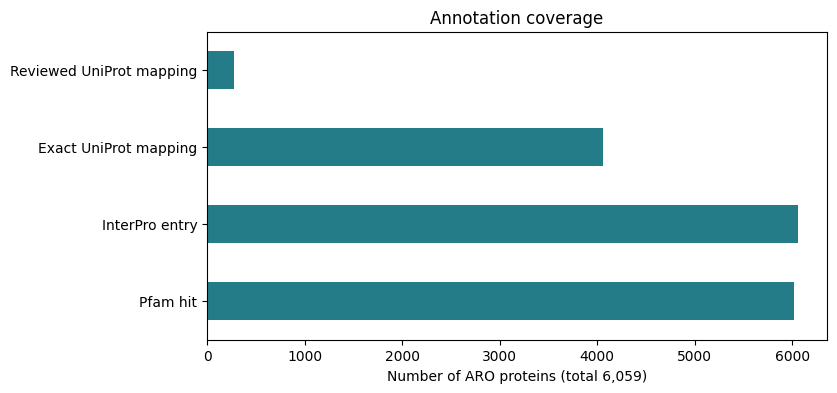

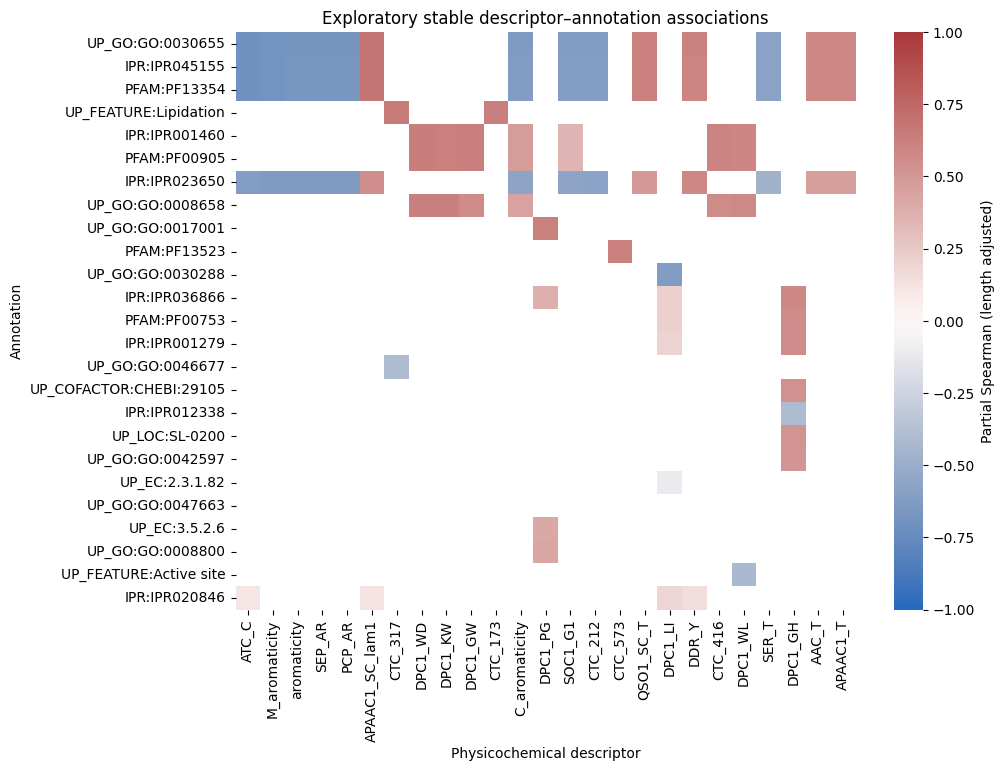

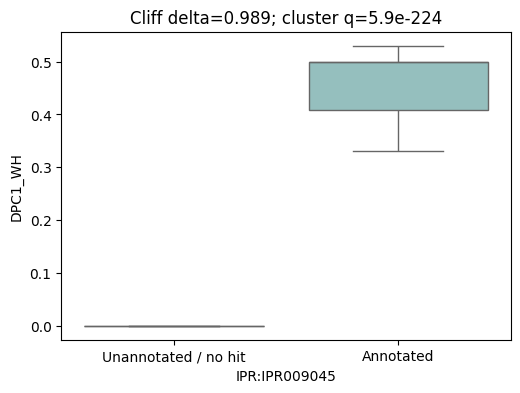

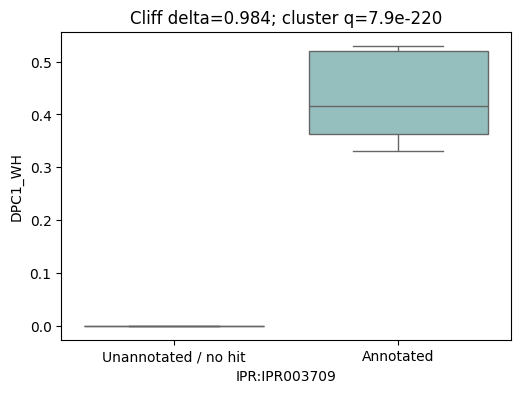

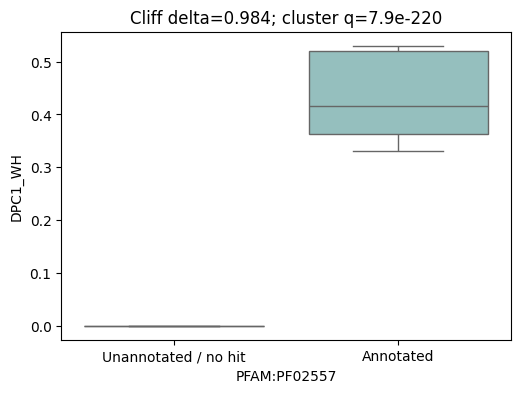

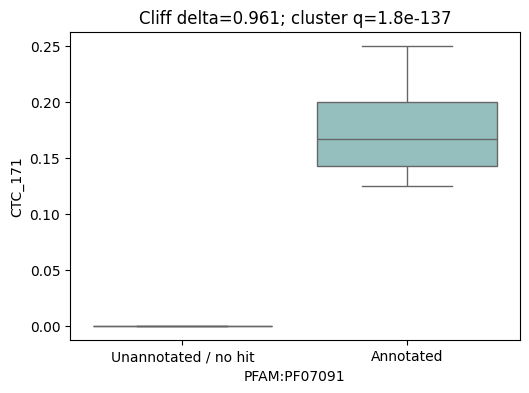

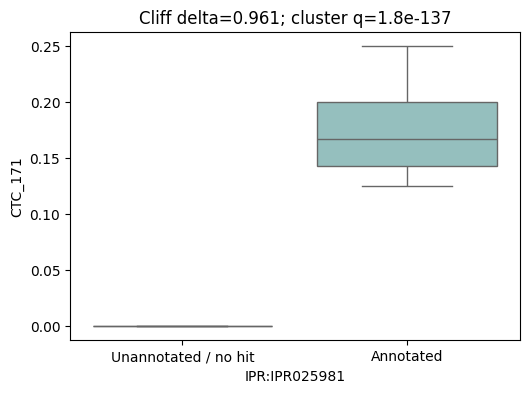

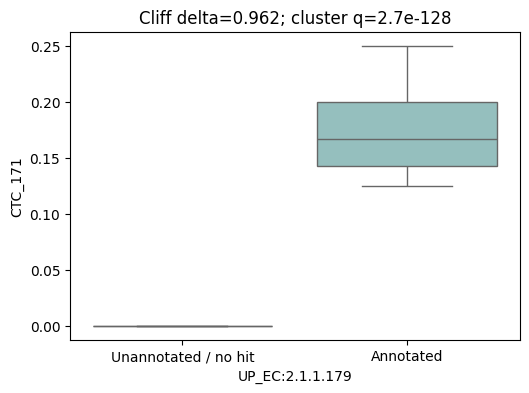

In [13]:
def save_figure(fig,name):
    fig.savefig(FIGURE_DIR/(name+".png"),dpi=300,bbox_inches="tight")
    fig.savefig(FIGURE_DIR/(name+".pdf"),bbox_inches="tight")
    plt.show()
    plt.close(fig)

coverage_counts=pd.Series({"Pfam hit":int(coverage.pfam_present.sum()),
    "InterPro entry":int(coverage.interpro_present.sum()),
    "Exact UniProt mapping":int(coverage.exact_match.sum()),
    "Reviewed UniProt mapping":int(coverage.reviewed.sum())})
fig,ax=plt.subplots(figsize=(8,4))
coverage_counts.plot.barh(ax=ax,color="#247c89")
ax.set(xlabel=f"Number of ARO proteins (total {len(meta):,})",title="Annotation coverage")
save_figure(fig,"annotation_coverage")

prevalence_rows=[]
for kind in ("family","drug_class","mechanism"):
    for label in sorted({x for memberships in meta[kind] for x in memberships}):
        selected=meta[kind].map(lambda memberships:label in memberships).to_numpy()
        if selected.sum()<MIN_TARGET_SUPPORT:
            continue
        for term in A_binary:
            y=A_binary[term].to_numpy()
            valid=np.isfinite(y)
            nin=int((valid&selected).sum()); nout=int((valid&~selected).sum())
            posin=int(((y==1)&selected).sum()); posout=int(((y==1)&~selected).sum())
            if not posin:
                continue
            prevalence_rows.append(dict(target_type=kind,label=label,annotation=term,
                annotation_name=term_names.get(term,term),n_target_total=int(selected.sum()),
                n_target_annotatable=nin,n_target_annotated=posin,
                target_prevalence=posin/nin if nin else np.nan,
                other_prevalence=posout/nout if nout else np.nan,
                n_other_annotatable=nout,n_other_annotated=posout))
prevalence=pd.DataFrame(prevalence_rows,columns=["target_type","label","annotation","annotation_name",
    "n_target_total","n_target_annotatable","n_target_annotated","target_prevalence",
    "other_prevalence","n_other_annotatable","n_other_annotated"])
save_csv(prevalence,"target_annotation_prevalence.csv")

if confirmed is not None:
    stable=confirmed.loc[confirmed.stable_exploratory].sort_values("q_cluster")
    if stable.empty:
        print("No associations passed the exploratory stability criteria; no significance heatmap generated.")
    else:
        feature_order=stable.groupby("feature").partial_spearman.apply(
            lambda v:v.abs().max()).nlargest(MAX_HEATMAP_FEATURES).index
        term_order=stable.groupby("annotation").partial_spearman.apply(
            lambda v:v.abs().max()).nlargest(MAX_HEATMAP_ANNOTATIONS).index
        plotted=stable.pivot(index="annotation",columns="feature",values="partial_spearman")
        plotted=plotted.reindex(index=term_order,columns=feature_order)
        save_csv(plotted,"annotation_physicochemical_heatmap_matrix.csv",index=True)
        fig,ax=plt.subplots(figsize=(max(10,len(feature_order)*.4),max(6,len(term_order)*.3)))
        sns.heatmap(plotted,mask=plotted.isna(),vmin=-1,vmax=1,center=0,cmap="vlag",ax=ax,
                    cbar_kws={"label":"Partial Spearman (length adjusted)"})
        ax.set(title="Exploratory stable descriptor–annotation associations",
               xlabel="Physicochemical descriptor",ylabel="Annotation")
        save_figure(fig,"annotation_physicochemical_heatmap")
        for rank,row in enumerate(stable.head(6).itertuples(),1):
            frame=pd.DataFrame({"value":X_phys[row.feature],"annotation":A_binary[row.annotation]}).dropna()
            fig,ax=plt.subplots(figsize=(5.8,4))
            sns.boxplot(data=frame,x="annotation",y="value",showfliers=False,ax=ax,color="#8ec6c5")
            ax.set(xticks=[0,1],xticklabels=["Unannotated / no hit","Annotated"],
                   xlabel=row.annotation,ylabel=row.feature,
                   title=f"Cliff delta={row.delta:.3f}; cluster q={row.q_cluster:.2g}")
            save_figure(fig,f"association_distribution_{rank:02d}")
    if SHAP_TOP_CSV is not None and Path(SHAP_TOP_CSV).is_file():
        shap_top=pd.read_csv(SHAP_TOP_CSV)
        needed={"target_type","label","feature","shap_importance"}
        if not needed<=set(shap_top):
            raise ValueError("Expected paired SHAP table with target_type, label, feature, shap_importance.")
        bridge=shap_top.merge(stable,on="feature",how="inner",validate="many_to_many")
        bridge=bridge.merge(prevalence,on=["target_type","label","annotation"],
                            how="left",validate="many_to_one",suffixes=("","_target"))
        bridge["interpretation"]="post_hoc_context_same_cohort"
        save_csv(bridge,"SHAP_feature_domain_context.csv")
    else:
        print("Optional SHAP bridge skipped: configured SHAP table is unavailable.")

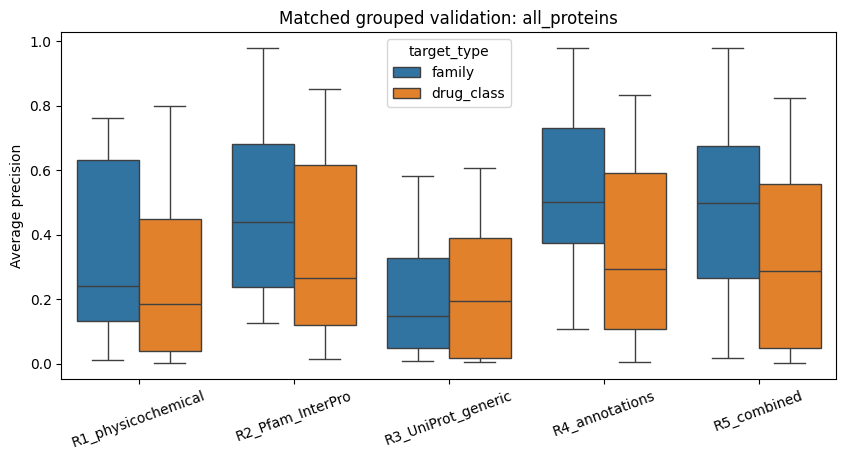

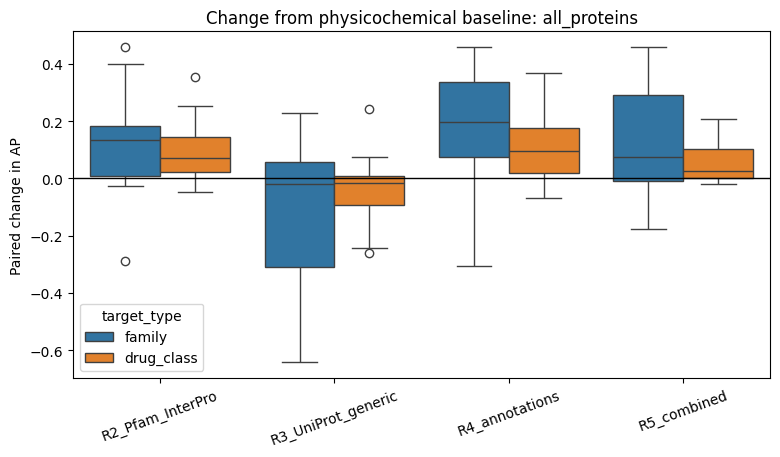

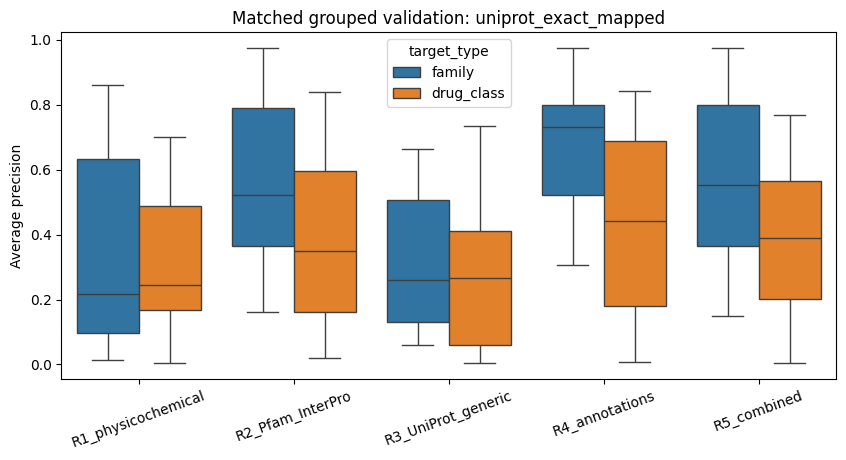

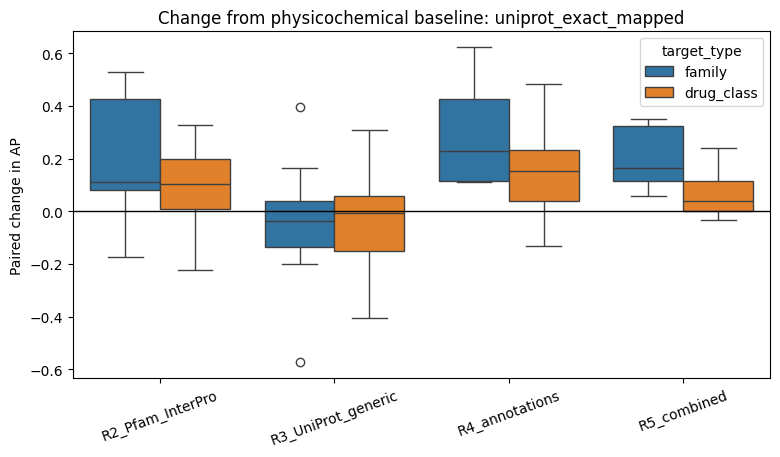

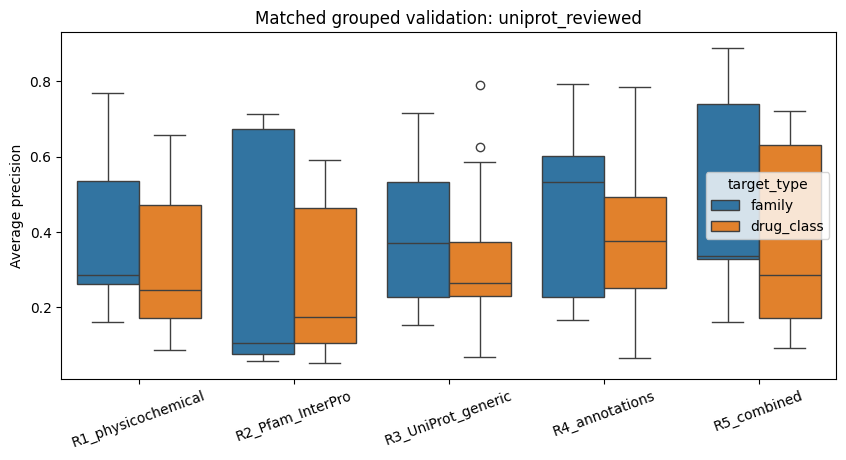

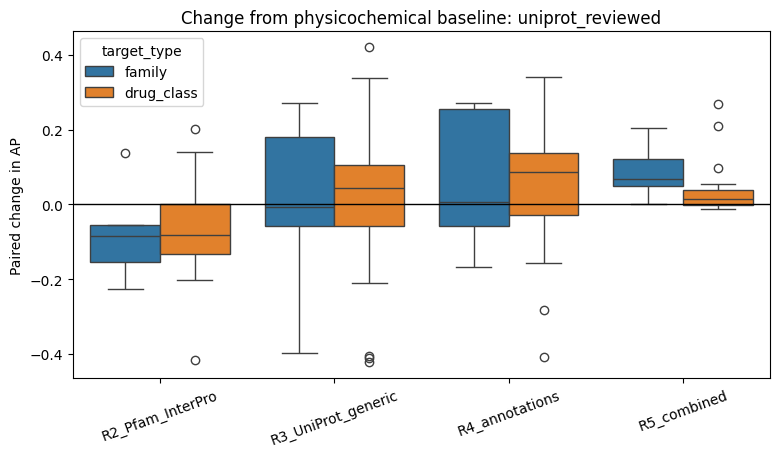

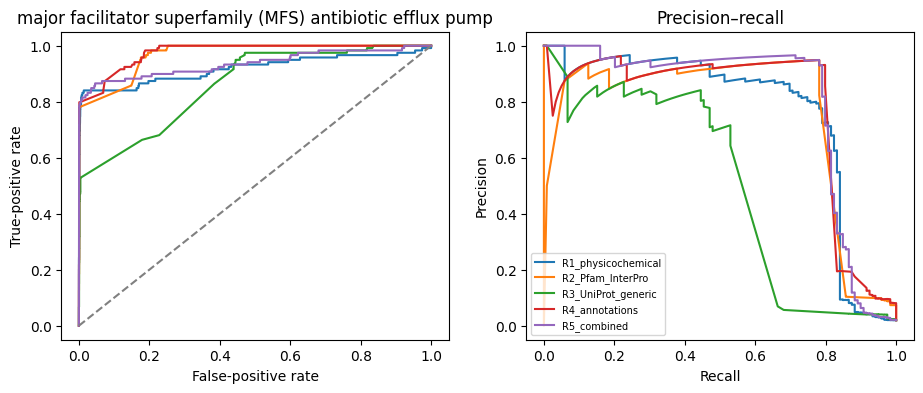

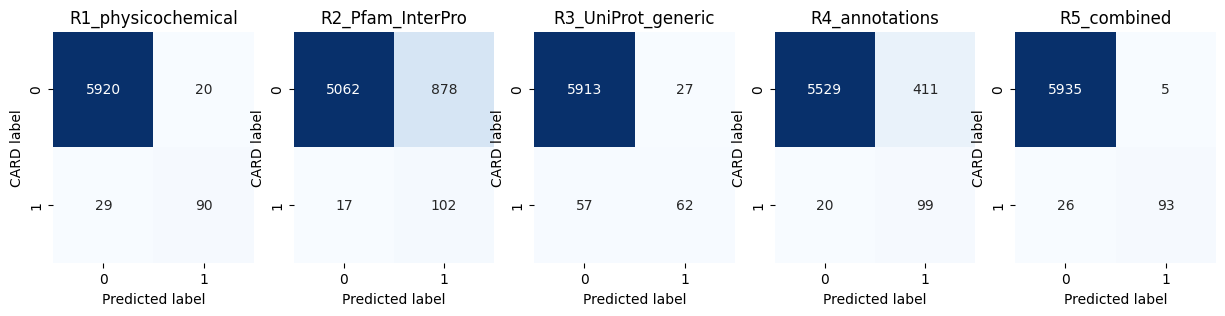

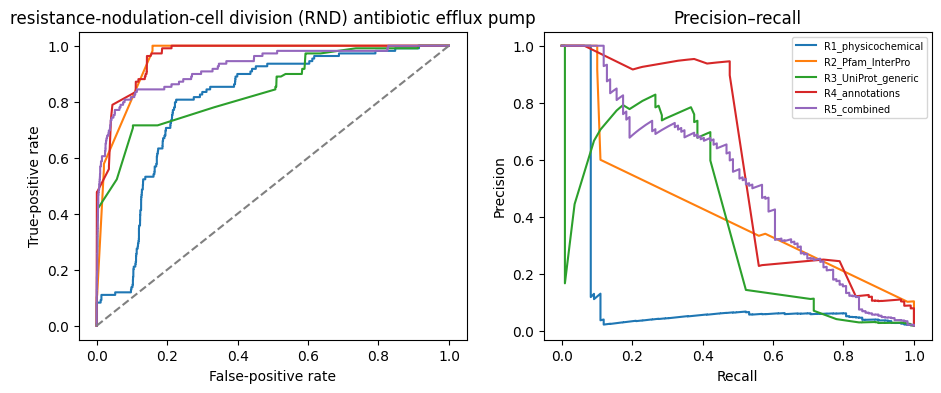

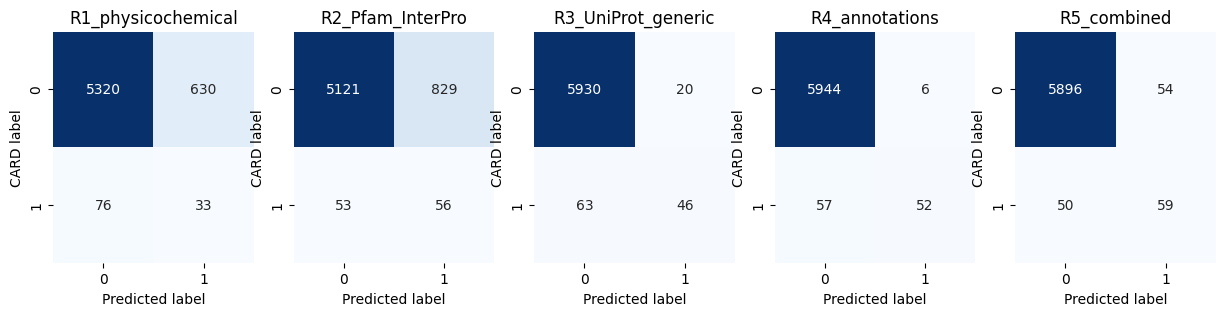

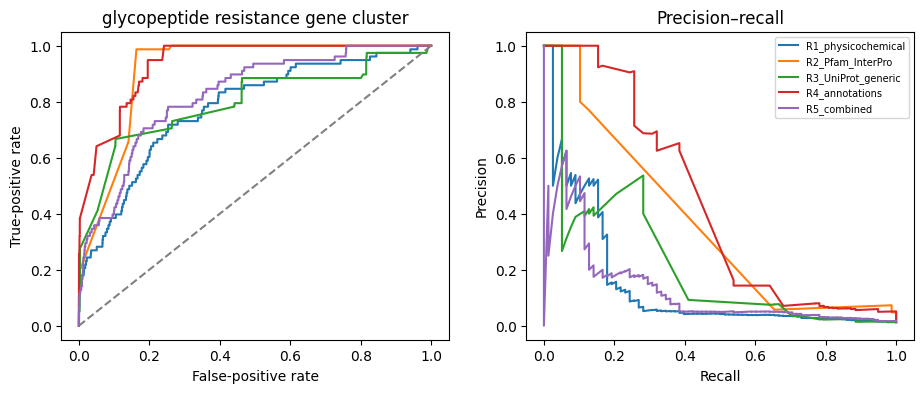

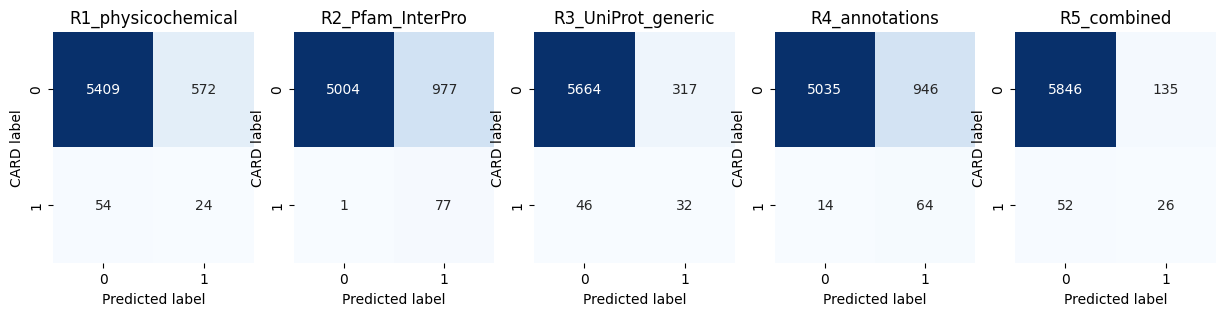

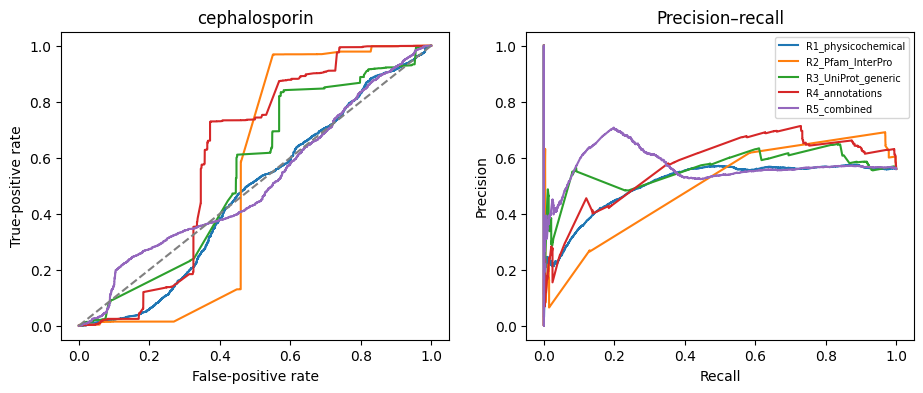

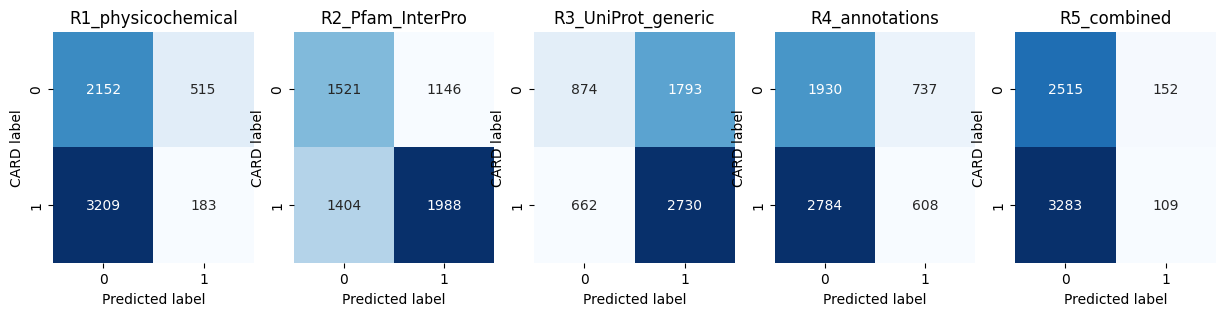

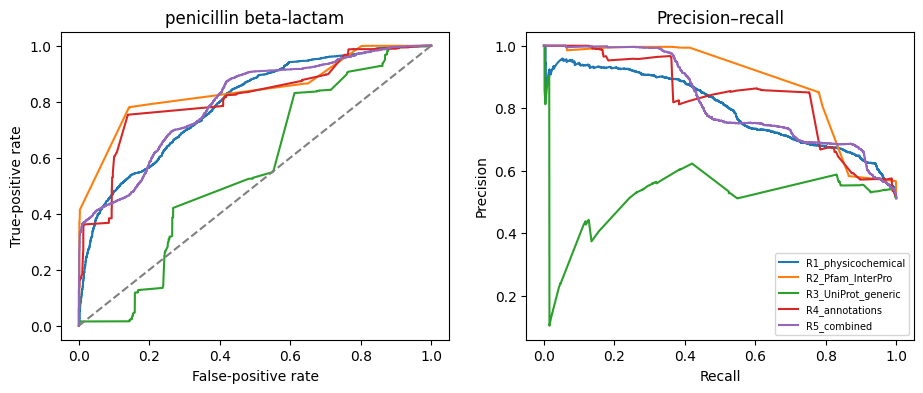

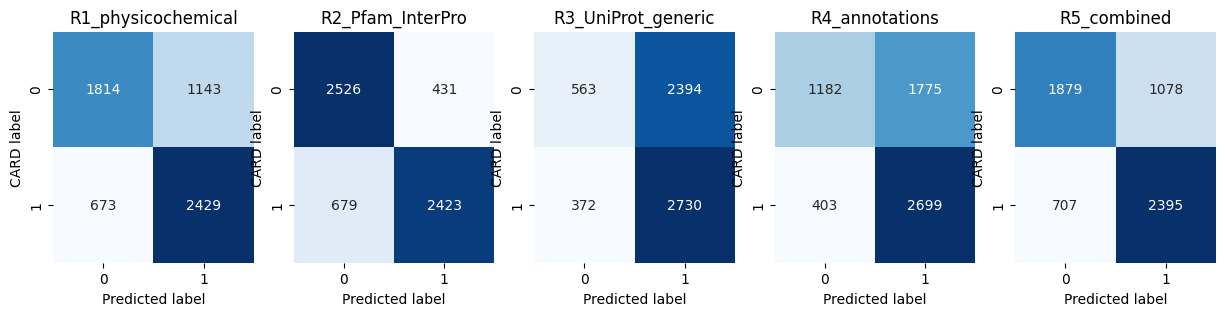

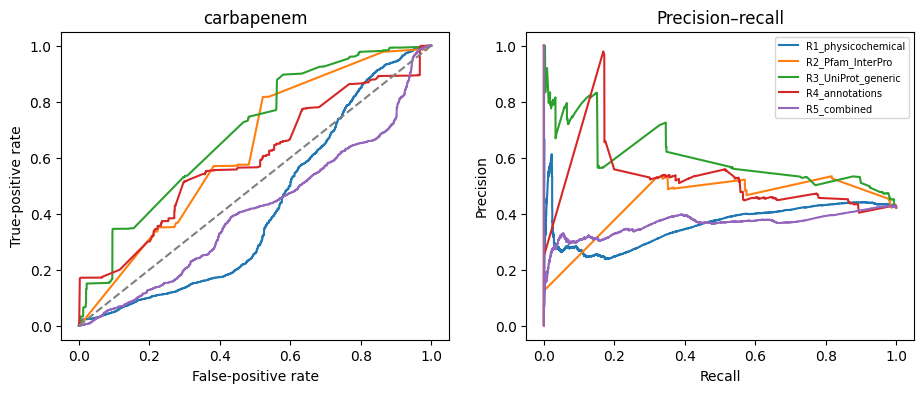

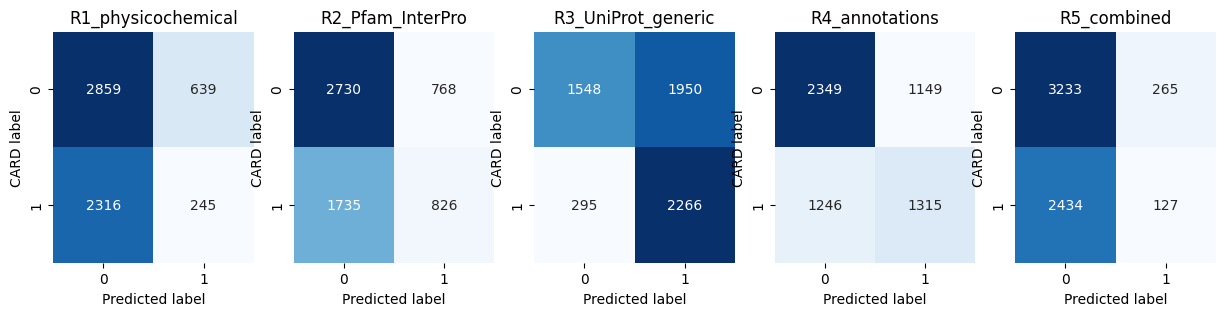

In [14]:
if metrics is not None and not metrics.empty:
    observed=metrics.loc[metrics["mode"].eq("observed")]
    for cohort,frame in observed.groupby("cohort"):
        fig,ax=plt.subplots(figsize=(10,4.5))
        sns.boxplot(data=frame,x="run",y="ap",hue="target_type",ax=ax)
        ax.set(title=f"Matched grouped validation: {cohort}",xlabel="",ylabel="Average precision")
        ax.tick_params(axis="x",rotation=20)
        save_figure(fig,"ablation_AP_"+cohort)
        subset=delta.loc[delta.cohort.eq(cohort)&~delta.run.eq("R1_physicochemical")]
        fig,ax=plt.subplots(figsize=(9,4.5))
        sns.boxplot(data=subset,x="run",y="delta_ap",hue="target_type",ax=ax)
        ax.axhline(0,color="black",linewidth=1)
        ax.set(title=f"Change from physicochemical baseline: {cohort}",xlabel="",ylabel="Paired change in AP")
        ax.tick_params(axis="x",rotation=20)
        save_figure(fig,"ablation_AP_delta_"+cohort)
    manifests=pd.DataFrame(prediction_files)
    primary=observed.loc[observed.cohort.eq("all_proteins")&observed.run.eq("R1_physicochemical")]
    # Representative targets are selected by support, not by performance.
    for kind in ("family","drug_class"):
        examples=primary.loc[primary.target_type.eq(kind)].sort_values(
            ["n_positive","label"],ascending=[False,True]).head(3)
        for ordinal,target in enumerate(examples.itertuples(),1):
            curves=manifests.loc[manifests.cohort.eq("all_proteins")&
                manifests["mode"].eq("observed")&manifests.target_type.eq(kind)&
                manifests.label.eq(target.label)]
            fig,axes=plt.subplots(1,2,figsize=(11,4))
            for curve in curves.itertuples():
                frame=pd.read_csv(curve.path)
                fpr,tpr,_=roc_curve(frame.y,frame.score)
                precision,recall,_=precision_recall_curve(frame.y,frame.score)
                axes[0].plot(fpr,tpr,label=curve.run)
                axes[1].plot(recall,precision,label=curve.run)
            axes[0].plot([0,1],[0,1],"--",color="grey")
            axes[0].set(xlabel="False-positive rate",ylabel="True-positive rate",title=target.label)
            axes[1].set(xlabel="Recall",ylabel="Precision",title="Precision–recall")
            axes[1].legend(fontsize=7)
            save_figure(fig,f"ablation_curves_{kind}_{ordinal:02d}")
            cmrows=observed.loc[observed.cohort.eq("all_proteins")&
                                observed.target_type.eq(kind)&observed.label.eq(target.label)]
            fig,axes=plt.subplots(1,len(cmrows),figsize=(3*len(cmrows),3))
            for ax,row in zip(np.atleast_1d(axes),cmrows.itertuples()):
                sns.heatmap(np.array([[row.tn,row.fp],[row.fn,row.tp]]),annot=True,fmt="d",
                            cbar=False,ax=ax,cmap="Blues")
                ax.set(title=row.run,xlabel="Predicted label",ylabel="CARD label")
            save_figure(fig,f"ablation_confusion_{kind}_{ordinal:02d}")

## 8. Generate the results-section draft after analyses finish

Set `WRITE_RESULTS_DRAFT=True` after association and ablation cells complete in this kernel. The draft uses computed statistics only.

Interpretation templates (**not findings**):
- “Proteins annotated with [domain] showed higher/lower [descriptor], with Cliff's delta [value] and cluster-adjusted q [value].”
- “After length adjustment, the whole-cluster bootstrap interval was [lower, upper].”
- “For the same test proteins and grouped folds, adding annotations changed median AP by [value].”

Pfam and integrated InterPro terms share underlying signatures. Whole-protein associations cannot localize a compositional change to a domain or prove a catalytic mechanism. Domain-segment feature extraction would be a separate experiment.

In [15]:
if WRITE_RESULTS_DRAFT:
    if confirmed is None or not completed_ablation:
        raise RuntimeError("Complete associations and ablations in this kernel before writing results.")
    RESULTS_DRAFT_PATH.parent.mkdir(parents=True,exist_ok=True)
    stable=confirmed.loc[confirmed.stable_exploratory].sort_values("q_cluster")
    lines=[
        "# Protein annotations and physicochemical associations", "",
        "## Analysis population and annotation coverage", "",
        f"The analysis included {len(meta):,} unique CARD ARO proteins with {X_phys.shape[1]:,} "
        "Pfeature and ProFET-style descriptors. Repeated drug-class rows were collapsed after "
        "numerical consistency checks. This is a protein-level adaptation of Ghosh et al.; "
        "outcomes are CARD family and drug-class memberships, not AST phenotypes.", "",
        f"InterProScan {ipr_release} completed scans for all {len(scanned_aros):,} proteins. "
        f"Pfam signatures were found in {int(coverage.pfam_present.sum()):,} proteins and integrated "
        f"InterPro annotations in {int(coverage.interpro_present.sum()):,}. Selected applications "
        f"were {', '.join(INTERPRO_APPLICATIONS)}.", "",
        f"Exact-sequence UniProtKB mappings were obtained for {int(uniprot_meta.exact_match.sum()):,} proteins; "
        f"{int(uniprot_meta.reviewed.sum()):,} representatives were reviewed. "
        "Unmapped records were retained as missing. Unannotated mapped records were not interpreted "
        "as experimentally established absence. Annotation-specific evidence was retained.", "",
        "## Physicochemical–annotation associations", "",
        f"The global analysis tested {len(confirmed):,} descriptor–annotation pairs. "
        f"{int(confirmed.screened_candidate.sum()):,} met screening criteria "
        f"(both BH q values < {FDR_THRESHOLD}, |Cliff's delta| >= {MIN_ABS_CLIFF_DELTA}, "
        f"and at least {MIN_CLUSTERS_PER_STATE} contributing clusters per state). "
        f"{int(confirmed.bootstrap_checked.sum()):,} candidates were checked with "
        f"{CLUSTER_BOOTSTRAPS:,} whole-cluster bootstrap replicates; "
        f"{len(stable):,} had length-adjusted intervals excluding zero.", "",
        "Mann–Whitney tests supplied descriptive effect screens. Cluster-robust ranked regression "
        "and cluster resampling addressed detected sequence dependence. These post-selection "
        "intervals are exploratory stability checks, not independent confirmation.", "",
    ]
    if MAX_CONFIRMATION_PAIRS is not None:
        lines.append(f"Bootstrap checking was capped at {MAX_CONFIRMATION_PAIRS}; unchecked candidates "
                     "were not classified as stable.\n")
    for row in stable.head(5).itertuples():
        direction="higher" if row.delta>0 else "lower"
        lines.append(
            f"- **{row.annotation} ({row.annotation_name}) — {row.feature}:** annotated proteins had "
            f"{direction} values (n={row.n_annotated} versus {row.n_unannotated}; "
            f"Cliff's delta={row.delta:.3f}; cluster-adjusted q={row.q_cluster:.3g}). "
            f"Length-adjusted partial Spearman correlation was {row.partial_spearman:.3f} "
            f"with exploratory 95% cluster-bootstrap interval "
            f"[{row.bootstrap_low:.3f}, {row.bootstrap_high:.3f}].")
    lines += ["", "## Matched family and drug-class ablations", "",
        "All blocks used the same eligible targets, outer test proteins and sequence groups within "
        "each cohort. Thresholds and preprocessing were fitted in training folds. UniProt identifiers, "
        "names, drug terms, EC/GO labels and resistance descriptions were excluded from predictors.", "",
        "| Cohort | Target | Run | Targets | Median AP | Median F1 | Median nMCC | Median paired AP change |",
        "|---|---|---|---:|---:|---:|---:|---:|"]
    for key,group in delta.groupby(["cohort","target_type","run"]):
        cohort,kind,run=key
        lines.append(f"| {cohort} | {kind} | {run} | {len(group)} | {group.ap.median():.3f} | "
                     f"{group.f1.median():.3f} | {group.nmcc.median():.3f} | {group.delta_ap.median():+.3f} |")
    null=metrics.loc[metrics["mode"].ne("observed")]
    lines += ["", "## Controls and limitations", ""]
    if null.empty:
        lines += ["No estimable shuffled-label control was completed; predictive gains require "
                  "this control before manuscript interpretation.", ""]
    else:
        lines += [f"Shuffled-label median nMCC was {null.nmcc.median():.3f} (chance reference 0.5). "
                  "Target-specific results and excluded null targets are listed separately. "
                  "One shuffle does not provide a permutation p-value.", ""]
    flags=int(null_summary.review_null.sum()) if not null_summary.empty else 0
    if flags:
        lines += [f"**Control review required:** {flags} summaries had null median nMCC more than "
                  "0.1 from 0.5. Investigate before claiming predictive improvements.", ""]
    lines += [
        "Pfam and corresponding integrated InterPro terms are not independent evidence. Domain "
        "annotations are derived from the same sequence whose descriptors are tested. Associations "
        "establish compositional relationships, not catalytic mechanisms or causal resistance. "
        "Family, phylogeny and curation depth remain potential confounders.", "",
        "Stratified panels and links to earlier SHAP importance are post-hoc analyses on the same "
        "protein collection. Cross-database agreement is not independent experimental validation. "
        "Exact UniProt matching limits applicability to novel sequences.", "",
        "## Reproducibility", "",
        f"- Cohort hash: {COHORT_HASH}",
        f"- Association hash: {ASSOC_HASH}",
        f"- Ablation hash: {ABLATION_HASH}",
        f"- Tables: {TABLE_DIR}",
        f"- Figures: {FIGURE_DIR}",
        "- Releases, retrieval times, mapping failures, versions, exclusions and folds are recorded "
        "in the accompanying manifests.", "",
        "## References", "",
        "- Ghosh et al. From sequence to signature: Machine learning uncovers multiscale feature "
        "landscapes that predict AMR across ESKAPE pathogens. bioRxiv, version 20 October 2025. "
        "https://doi.org/10.1101/2025.07.03.663053 (preprint).",
        "- InterProScan: https://www.ebi.ac.uk/interpro/download/InterProScan/",
        "- UniProt API: https://www.uniprot.org/help/id_mapping_prog", "",
        "*Draft generated from completed analyses; review biological interpretation before publication.*",
    ]
    temporary=RESULTS_DRAFT_PATH.with_suffix(".md.tmp")
    temporary.write_text("\n".join(lines)+"\n")
    temporary.replace(RESULTS_DRAFT_PATH)
    print("Results draft:",RESULTS_DRAFT_PATH)
else:
    print("Results-draft writing disabled; enable it after completing analyses.")

Results draft: /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/project_documentation/Protein_Annotation_Physicochemical_Association_Results.md


## 9. Completion checks and output guide

All tables are written under the configured `TABLE_DIR`.

| Output | Meaning |
|---|---|
| `protein_manifest.csv`, `physicochemical_matrix.csv` | One ARO per row, sequence provenance and raw descriptors |
| `pfam_domain_binary.csv`, `pfam_domain_count.csv`, `pfam_domain_scores.csv` | Protein × Pfam annotation matrices |
| `interpro_annotation_binary.csv` | Protein × integrated InterPro term |
| `uniprot_annotation_binary.csv`, `uniprot_structured_context.csv` | Protein × UniProt annotation; missing mappings stay NaN |
| `protein_annotation_long.csv`, `uniprot_annotation_long.csv` | Source annotations, coordinates and evidence |
| `annotation_coverage.csv`, `uniprot_mapping_audit.csv` | Coverage, no hits, unmapped accessions and sequence mismatches |
| `physicochemical_annotation_associations.csv` | Effect sizes, p/q values, adjusted correlations, bootstrap intervals |
| `conditional_domain_score_associations.csv` | Descriptor correlations with scores/counts among domain-positive proteins |
| `target_annotation_prevalence.csv` | Domain/function context for CARD families, drugs and mechanisms |
| `SHAP_feature_domain_context.csv` | Optional connection to earlier important descriptors |
| `stratified_association_summary.csv` | Counts and paths for post-hoc panels |
| `ablation_metrics.csv`, `ablation_paired_deltas.csv` | Matched family/drug-class performance |
| `ablation_fold_manifest.csv`, `ablation_exclusions.csv` | Folds and target exclusions |
| `shuffled_label_control_summary.csv` | Null-control diagnostics |

Add large tools/data/cache directories to your own Git ignore rules if needed. This notebook does not edit ignore files or install/register environments.

Rerun unchanged inputs to reuse completed annotation/model/bootstrap caches. Changed inputs, releases, model parameters or groups create new fingerprinted analysis caches. Summary CSVs and the draft use fixed configured paths; choose another `OUTPUT_DIR` to preserve a separate experiment.

In [ ]:
# These assertions run only when YOU execute this cell.
assert len(meta)==EXPECTED_PROTEINS and meta.index.is_unique
assert X_phys.shape==(EXPECTED_PROTEINS,EXPECTED_FEATURE_COUNT)
assert set(scanned_aros)==set(meta.index)
assert sequence_groups.notna().all()
assert not U_terms.loc[~uniprot_meta.exact_match].notna().any().any()
assert not U_numeric.loc[~uniprot_meta.exact_match].notna().any().any()
assert all(a in meta.index for a in selected_entries)
assert all(e["sequence"]["value"].upper()==records[a]["sequence"]
           for a,e in selected_entries.items())
if completed_ablation:
    folds=pd.DataFrame(fold_manifests)
    assert not folds.duplicated(["cohort","aro_accession"]).any()
    assert folds.groupby(["cohort","cluster_id"]).fold.nunique().le(1).all()
if confirmed is not None:
    assert confirmed.loc[confirmed.stable_exploratory,"bootstrap_checked"].all()
print("Cohort, annotation, mapping, and available analysis invariants passed.")